* Imports
* Problem Framing
* Understand Data, EDA, and Insights
* Data Preprocessing and Feature Engineering Pipeline
* Modeling Pipeline
* Evaluation
* Hyperparameter Tuning
* saving pipelines and best model for resuability

### Imports

In [19]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# extra imports for the clustering work
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.neighbors import NearestCentroid
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)
from sklearn.base import BaseEstimator, ClusterMixin
from sklearn.metrics import pairwise_distances
from scipy.cluster.hierarchy import linkage, dendrogram
import joblib, json

sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

# Problem framing

What is the problem?

inefficiency in retail marketing, the retailer treats every customer the same way, sending identical emails, discounts, and ads to a brand-new buyer, a loyal high spender, and someone who hasn’t bought anything in a year. This wastes marketing budget and leaves money on the table

The user is the Retailer's marketing managesrs

Proposed Solution
Build an internal customer intelligence dashboard powered by a two-stage machine learning pipeline:

1- Customer Segmentation (Unsupervised Learning): Group customers into distinct behavioral cohorts (e.g., VIPs, At-Risk, New Buyers) based on RFM metrics (Recency, Frequency, Monetary value) to scale personalized messaging.

2- 90-Day Spend Prediction (Supervised Regression): Forecast each customer's expected revenue over the next 90 days so teams can quantify financial value and revenue at risk.

Actionable Output & Impact

When a marketer looks up a Customer ID in the dashboard, the system displays their behavioral segment, predicted 90-day spend, and a tailored marketing action (such as offering VIP perks to high spenders, sending win-back discounts to at-risk shoppers, or cutting ad spend on low-engagement accounts). This bridges historical transaction data with forward-looking financial forecasting.

**Decision, target and metric (clustering part)**

* **Decision the model supports:** which marketing treatment each customer gets (reward, win back, nurture, or stop spending on).
* **Target variable:** none for the segmentation, because it is unsupervised. The only "target" in the project is the 90-day spend, which belongs to the regression stage (not covered in this part).
* **Metric that matters:**
  * *Technical:* **Silhouette score** (how well separated the segments are) together with Davies-Bouldin as a second opinion. I choose silhouette because there are no labels to compare against, so cluster quality has to be judged by separation and compactness.
  * *Business:* segments must be **stable** (the same customers land in the same group when the data is resampled), **big enough to act on**, and **different enough in R/F/M** that a marketer can describe them in one sentence.

# EDA, Understand Data, and Insights

## Understand Data

I have 2 data sets, one from the end of 2009 to 2010 and the ohter from 2010 to the end of 2011, Which means I have 2 years of transaction data.

Each one of the is about 500k row with the same columns

First I'll work on the first 500k row for simplicty

Column Description:

* Invoice: A unique 6-digit transaction ID number assigned to each order. (If it starts with the letter 'C', it represents a cancelled order or a return.)
* StockCode: A unique product code assigned to each distinct item.
* Description: The text name or title of the product being purchased.
* Quantity: The number of units of a specific product bought in that transaction line.
* InvoiceDate: The exact date and timestamp when the transaction took place.
* Price: The unit price of the product (cost per single item).
* Customer ID: A unique identifier number assigned to each customer.
* Country: The name of the country where the customer is located. 

**Data summary**

* **Source:** UCI *Online Retail II* (a UK online gift-ware retailer, many customers are wholesalers). Here I use the first sheet only: 1 Dec 2009 to 9 Dec 2010.
* **Size:** 525,461 rows x 8 columns, 4,383 customers (Customer ID is missing on about 20% of rows).
* **Class balance:** not applicable, the segmentation has no label. (Balance will matter only if the regression stage needs it.)

In [12]:
df = pd.read_excel('/kaggle/input/datasets/lordmostafa199/online-retail-ii/online_retail_II.xlsx')
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 525461 entries, 0 to 525460
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      525461 non-null  object        
 1   StockCode    525461 non-null  object        
 2   Description  522533 non-null  object        
 3   Quantity     525461 non-null  int64         
 4   InvoiceDate  525461 non-null  datetime64[ns]
 5   Price        525461 non-null  float64       
 6   Customer ID  417534 non-null  float64       
 7   Country      525461 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 32.1+ MB


In [5]:
def view_features(df):
    global categorical_cols, categorical_cols_list, numerical_cols, numerical_cols_list
    categorical_cols = df.select_dtypes(include=['object'])
    categorical_cols_list = categorical_cols.columns.to_list()
    numerical_cols = df.select_dtypes(include=['float64', 'int64', 'int32'])
    numerical_cols_list = numerical_cols.columns.to_list()
    num_categorical_cols = categorical_cols.shape[1]
    print(f" they are {num_categorical_cols} categorical features and 3 numerical feature\n")
    print(f" Categorical Features:\n {categorical_cols_list}\n\n Numerical Features:\n {numerical_cols_list}")
view_features(df)

 they are 4 categorical features and 3 numerical feature

 Categorical Features:
 ['Invoice', 'StockCode', 'Description', 'Country']

 Numerical Features:
 ['Quantity', 'Price', 'Customer ID']


In [7]:
df.isna().sum()

Invoice             0
StockCode           0
Description      2928
Quantity            0
InvoiceDate         0
Price               0
Customer ID    107927
Country             0
dtype: int64

* We drop should drop dupplicates and missing Customers ID
* the missing description i will compare it with other description's price and select the closest description based on the price similarity.

In [9]:
df.duplicated().sum()

6865

In [10]:
df.describe()

,Quantity,InvoiceDate,Price,Customer ID
count,525461.000000,525461,525461.000000,417534.000000
mean,10.337667,2010-06-28 11:37:36.845017856,4.688834,15360.645478
min,-9600.000000,2009-12-01 07:45:00,-53594.360000,12346.000000
25%,1.000000,2010-03-21 12:20:00,1.250000,13983.000000
50%,3.000000,2010-07-06 09:51:00,2.100000,15311.000000
75%,10.000000,2010-10-15 12:45:00,4.210000,16799.000000
max,19152.000000,2010-12-09 20:01:00,25111.090000,18287.000000
std,107.424110,NaN,146.126914,1680.811316


* I need to figure out the -ve values in price and Quantity
* Also the Huge +ve values in price and Quantity
* then see what to do about them

In [13]:
df['Price'].value_counts()

Price
1.25      53932
0.85      40721
2.95      38094
1.65      35627
2.10      24701
          ...  
864.59        1
194.12        1
6.85          1
172.21        1
85.79         1
Name: count, Length: 1606, dtype: int64

In [9]:
print("Counting Unique Data in each categorical column")
for i in range(4):
    print(f"\n\n {categorical_cols_list[i]} Unique Data: {categorical_cols[categorical_cols_list[i]].nunique()}")
    print(f" repeated: {df.shape[0] - categorical_cols[categorical_cols_list[i]].nunique()}")

Counting Unique Data in each categorical column


 Invoice Unique Data: 28816
 repeated: 496645


 StockCode Unique Data: 4632
 repeated: 520829


 Description Unique Data: 4681
 repeated: 520780


 Country Unique Data: 40
 repeated: 525421


##### number of Customers I have

In [13]:
total_customers = df['Customer ID'].nunique()
print(f"Total Unique Customers: {total_customers}")

Total Unique Customers: 4383


#### normalize the data

In [26]:
print(df['Country'].str.strip().str.lower().nunique())
print(df['Description'].str.strip().str.lower().nunique())

40
4630


In [27]:
df['Description'] = df['Description'].str.strip().str.lower().nunique()

In [11]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,NaN,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,NaN,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,NaN,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


<Axes: xlabel='Price', ylabel='Count'>

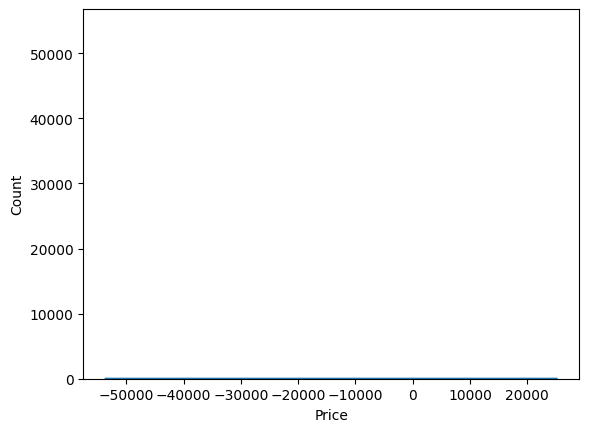

In [8]:
sns.histplot(df['Price'], kde= True)

## Outliers

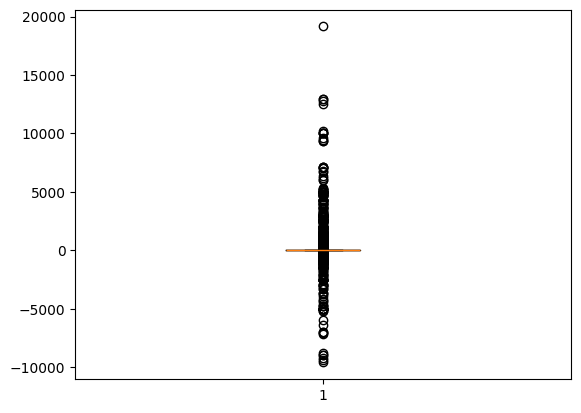

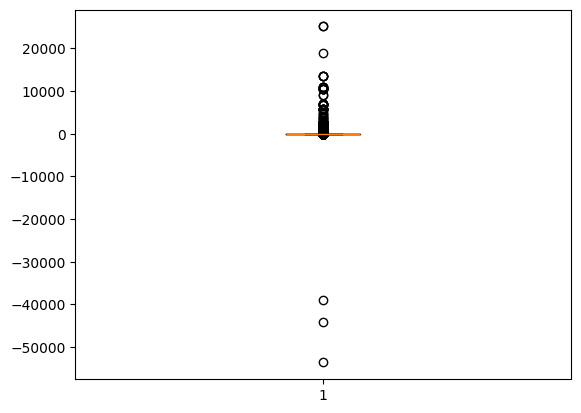

In [21]:
plt.boxplot(numerical_cols['Quantity'])
plt.show();

plt.boxplot(numerical_cols['Price'])
plt.show();

* Very bad Outliers needed to be removed or clipped

<Axes: >

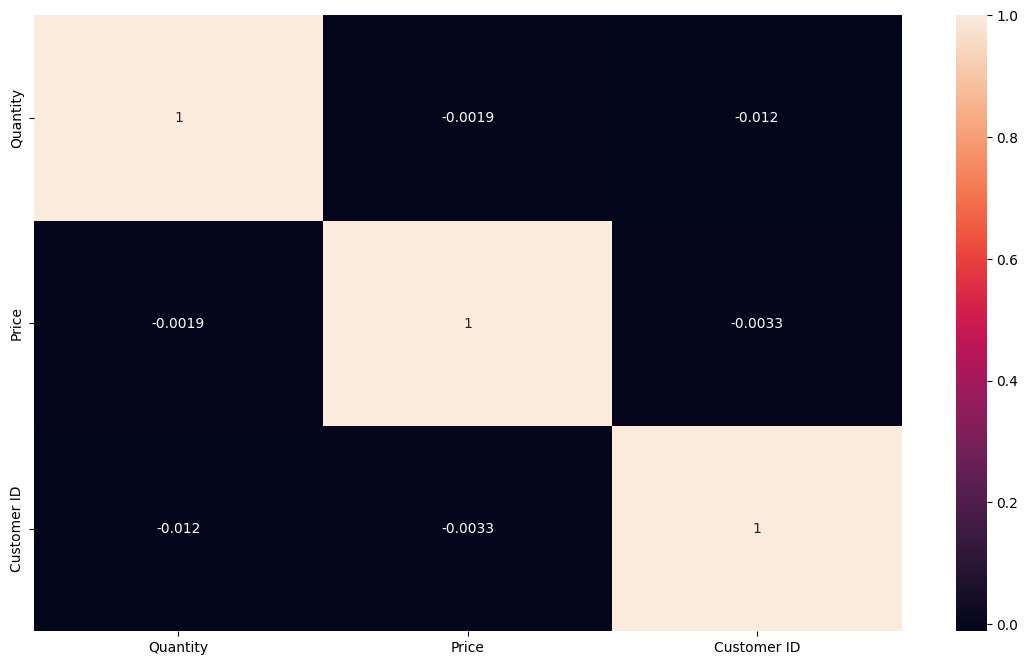

In [23]:
plt.figure(figsize=(14,8))
sns.heatmap(df.corr(numeric_only=True), annot=True)

## Continued EDA

The `describe()` above showed negative and enormous values. First I count exactly what kind of "bad" rows exist, then I package the cleaning rules in a small helper file so that the EDA and the final pipeline use **the same rules**.

In [18]:
n = len(df)
codes = df['StockCode'].astype(str)
quality = pd.Series({
    'Missing Customer ID': df['Customer ID'].isna().sum(),
    'Exact duplicate rows': df.duplicated().sum(),
    'Cancelled invoices (Invoice starts with C)': df['Invoice'].astype(str).str.startswith('C').sum(),
    'Quantity <= 0': (df['Quantity'] <= 0).sum(),
    'Price <= 0': (df['Price'] <= 0).sum(),
    'Non-product StockCode (POST, M, ADJUST, BANK CHARGES...)': (~codes.str.match(r'^\d{5}')).sum(),
}).to_frame('rows')
quality['% of all rows'] = (quality['rows'] / n * 100).round(2)
quality

,rows,% of all rows
Missing Customer ID,107927,20.54
Exact duplicate rows,6865,1.31
Cancelled invoices (Invoice starts with C),10206,1.94
Quantity <= 0,12326,2.35
Price <= 0,3690,0.70
"Non-product StockCode (POST, M, ADJUST, BANK CHARGES...)",3097,0.59


Cancellations, negative quantities and non-product codes (postage, manual adjustments, bank charges) are not customer purchases, so they would distort "how much does this customer spend". Missing IDs cannot be tied to a customer at all.

In [19]:
%%writefile rfm_utils.py
import numpy as np
import pandas as pd


def clean_transactions(df, verbose=True):
    """Rule-based cleaning. Nothing is learned from the data, so it is safe to run before the train/test split."""
    steps = []
    d = df.copy()
    steps.append(('raw data', len(d)))
    d = d.dropna(subset=['Customer ID']);                              steps.append(('drop missing Customer ID', len(d)))
    d = d.drop_duplicates();                                           steps.append(('drop duplicate rows', len(d)))
    d = d[~d['Invoice'].astype(str).str.startswith('C')];              steps.append(('drop cancelled invoices (C...)', len(d)))
    d = d[(d['Quantity'] > 0) & (d['Price'] > 0)];                     steps.append(('drop Quantity<=0 or Price<=0', len(d)))
    d = d[d['StockCode'].astype(str).str.match(r'^\d{5}')];           steps.append(('drop non-product codes', len(d)))
    d = d.copy()
    d['Customer ID'] = d['Customer ID'].astype(int)
    d['Spend'] = d['Quantity'] * d['Price']
    if verbose:
        log = pd.DataFrame(steps, columns=['step', 'rows_left'])
        log['rows_removed'] = (-log['rows_left'].diff()).fillna(0).astype(int)
        print(log.to_string(index=False))
    return d


def build_rfm(clean, snapshot_date=None):
    """One row per customer: Recency (days since last order), Frequency (number of orders), Monetary (total spend)."""
    if snapshot_date is None:
        snapshot_date = clean['InvoiceDate'].max().normalize() + pd.Timedelta(days=1)
    g = clean.groupby('Customer ID')
    rfm = pd.DataFrame({
        'Recency': (snapshot_date - g['InvoiceDate'].max()).dt.days,
        'Frequency': g['Invoice'].nunique(),
        'Monetary': g['Spend'].sum(),
    })
    return rfm, snapshot_date

Overwriting rfm_utils.py


In [20]:
from rfm_utils import clean_transactions, build_rfm

clean = clean_transactions(df)
print(f"\nCustomers left: {clean['Customer ID'].nunique()}")

                          step  rows_left  rows_removed
                      raw data     525461             0
      drop missing Customer ID     417534        107927
           drop duplicate rows     410763          6771
drop cancelled invoices (C...)     400947          9816
  drop Quantity<=0 or Price<=0     400916            31
        drop non-product codes     399552          1364

Customers left: 4285


### Univariate analysis (cleaned transactions)

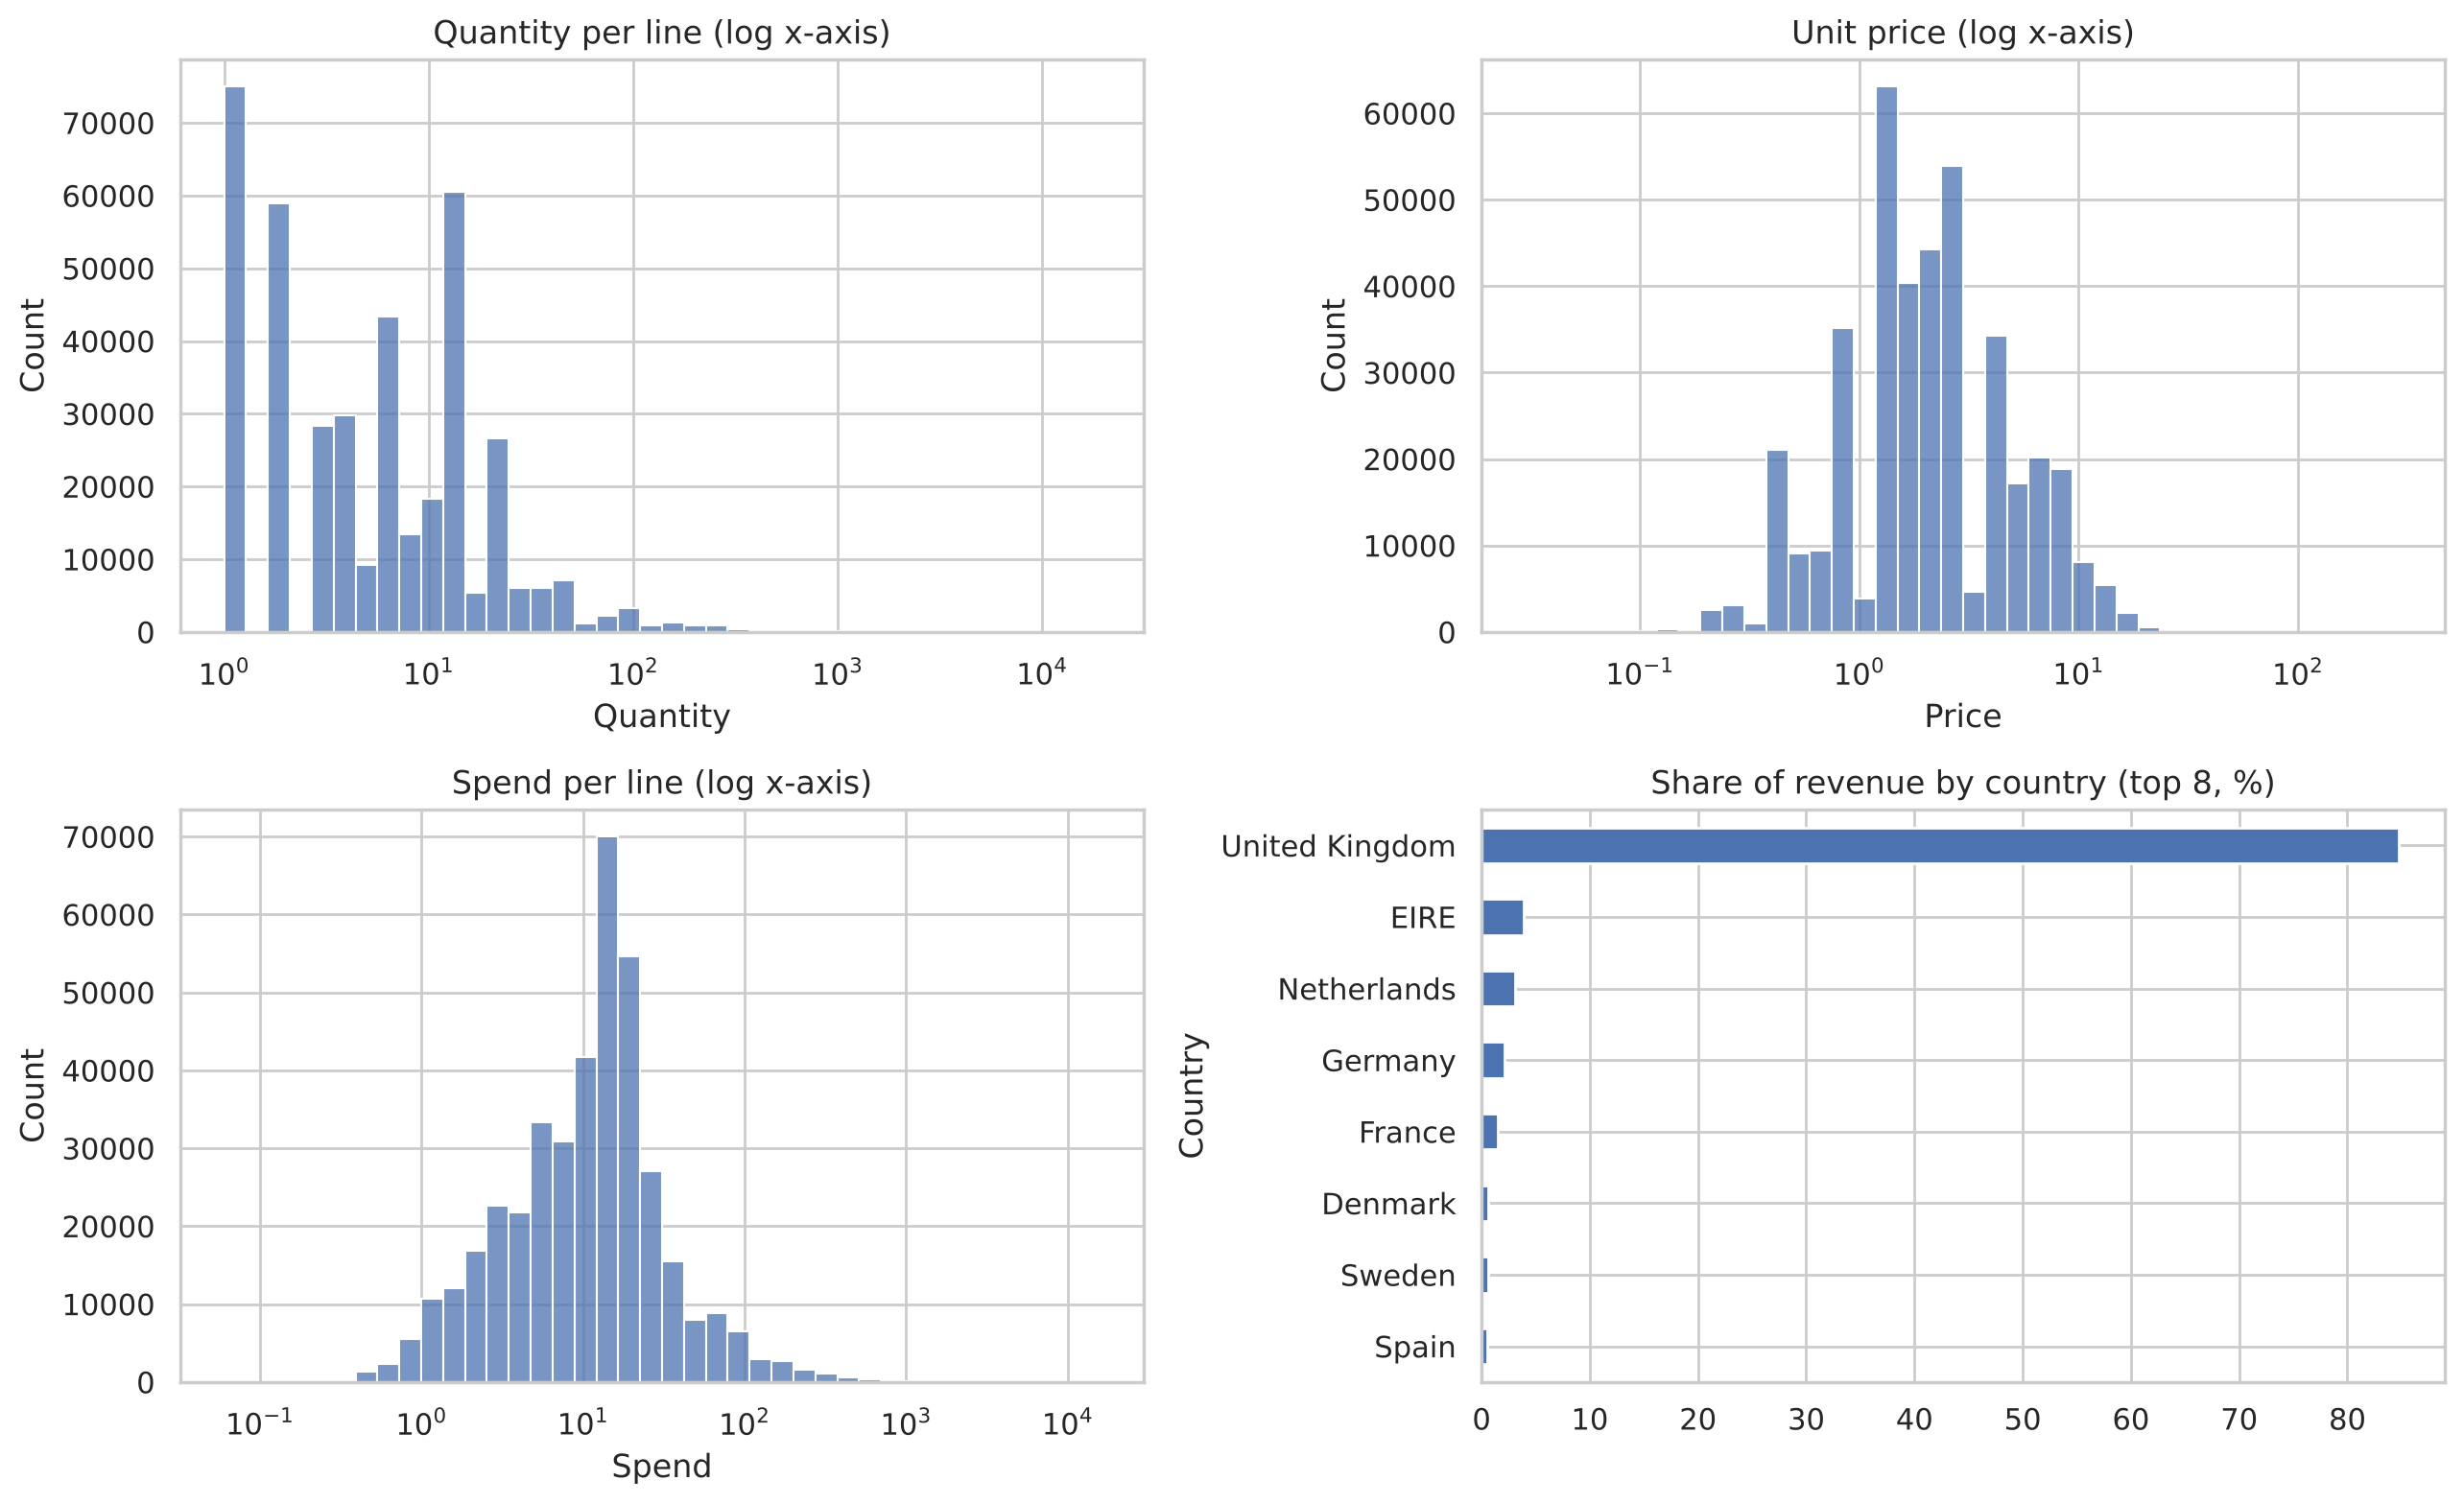

UK share of revenue: 84.8%


In [21]:
fig, ax = plt.subplots(2, 2, figsize=(13, 8))
sns.histplot(clean['Quantity'], log_scale=True, bins=40, ax=ax[0, 0]).set(title='Quantity per line (log x-axis)')
sns.histplot(clean['Price'], log_scale=True, bins=40, ax=ax[0, 1]).set(title='Unit price (log x-axis)')
sns.histplot(clean['Spend'], log_scale=True, bins=40, ax=ax[1, 0]).set(title='Spend per line (log x-axis)')
top_countries = clean.groupby('Country')['Spend'].sum().sort_values(ascending=False).head(8)
(top_countries / clean['Spend'].sum() * 100).plot.barh(ax=ax[1, 1]).set(title='Share of revenue by country (top 8, %)')
ax[1, 1].invert_yaxis()
plt.tight_layout(); plt.show()
print(f"UK share of revenue: {top_countries['United Kingdom'] / clean['Spend'].sum():.1%}")

### Bivariate analysis

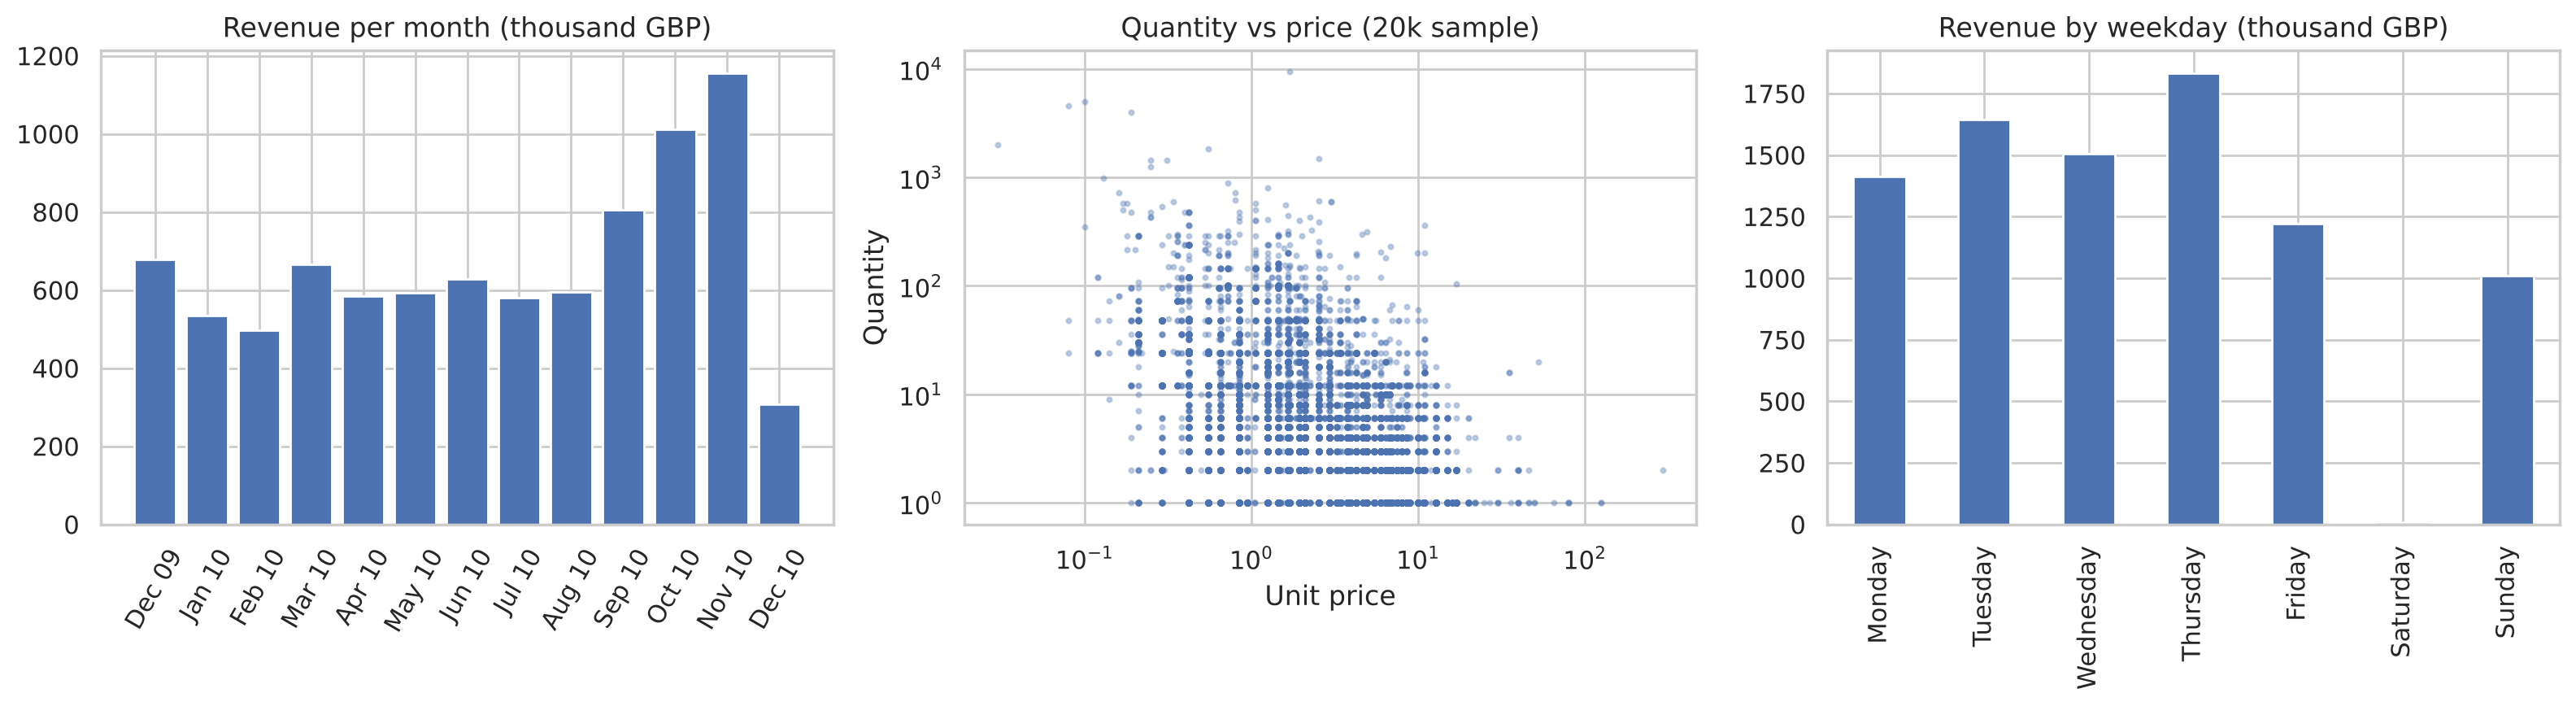

In [22]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))

monthly = clean.set_index('InvoiceDate')['Spend'].resample('MS').sum() / 1000
ax[0].bar(monthly.index.strftime('%b %y'), monthly.values)
ax[0].set(title='Revenue per month (thousand GBP)'); ax[0].tick_params(axis='x', rotation=60)

s = clean.sample(20000, random_state=RANDOM_STATE)
ax[1].scatter(s['Price'], s['Quantity'], s=4, alpha=.3)
ax[1].set(xscale='log', yscale='log', xlabel='Unit price', ylabel='Quantity', title='Quantity vs price (20k sample)')

clean.groupby(clean['InvoiceDate'].dt.day_name())['Spend'].sum().reindex(
    ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']).div(1000).plot.bar(ax=ax[2]).set(
    title='Revenue by weekday (thousand GBP)', xlabel='')
plt.tight_layout(); plt.show()

### Multivariate analysis

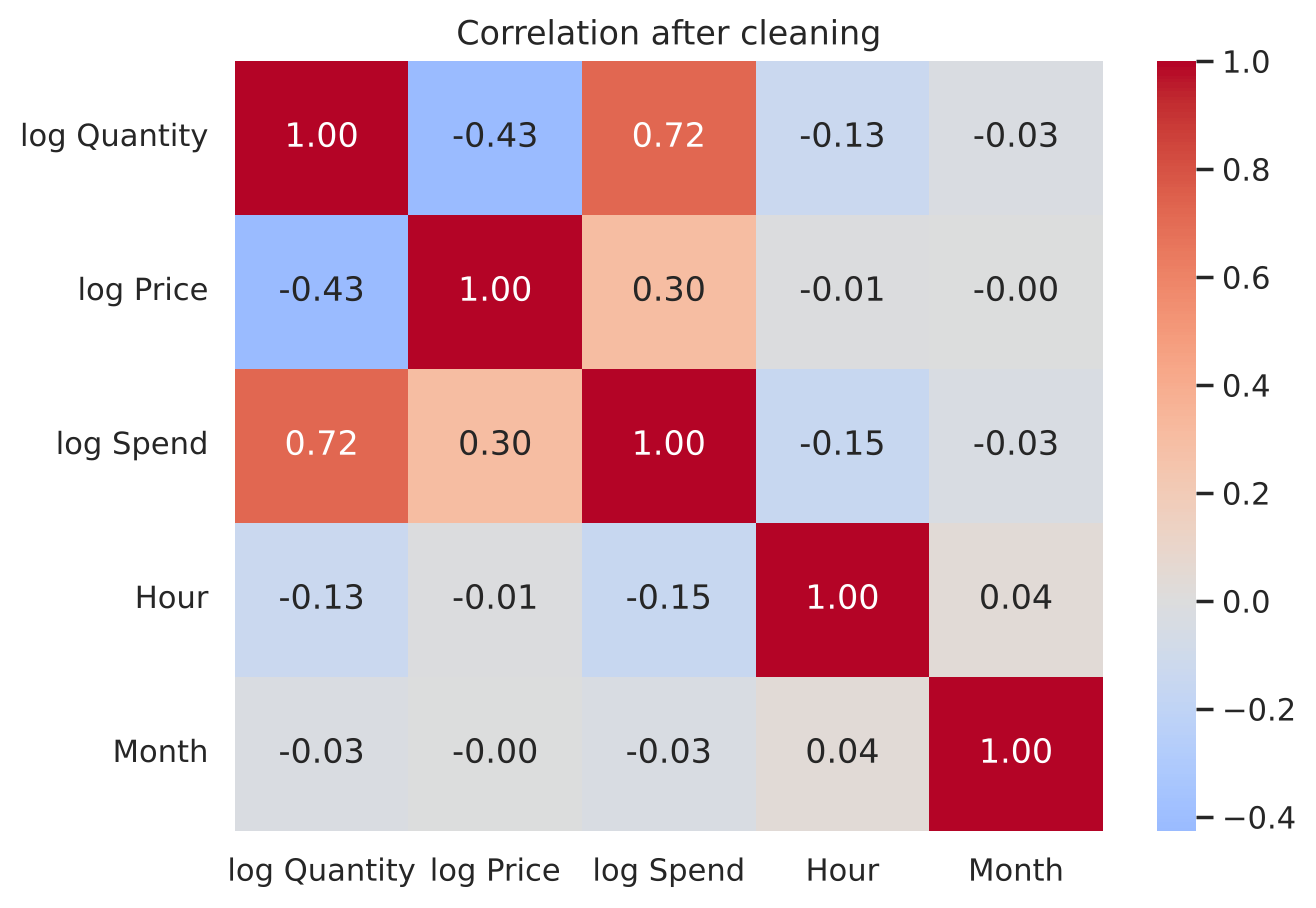

In [23]:
m = pd.DataFrame({
    'log Quantity': np.log1p(clean['Quantity']),
    'log Price': np.log1p(clean['Price']),
    'log Spend': np.log1p(clean['Spend']),
    'Hour': clean['InvoiceDate'].dt.hour,
    'Month': clean['InvoiceDate'].dt.month,
})
plt.figure(figsize=(7, 5))
sns.heatmap(m.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation after cleaning'); plt.show()

In [24]:
# how concentrated is revenue? (Pareto check at customer level)
cust_spend = clean.groupby('Customer ID')['Spend'].sum().sort_values(ascending=False)
top20 = cust_spend.head(int(len(cust_spend) * 0.2)).sum() / cust_spend.sum()
print(f"Top 20% of customers generate {top20:.0%} of revenue")
print(f"Customers with only 1 invoice: {(clean.groupby('Customer ID')['Invoice'].nunique() == 1).mean():.0%}")

Top 20% of customers generate 73% of revenue
Customers with only 1 invoice: 33%


## Insights

How can I make a good cluster that really identify who buy from who does not?
* I need to Assign each customer to a specific cluster, also I should Extract RFM (Recency, Frequency, Monetary) features
* I think it is a good idea to cluster customers into those 4 specific groups (VIP, At-Risk, Inactive, New Buyer)

What action should the app suggest for each group?
The app maps each cluster to a specific rule-based marketing playbook:

* VIPs: Send exclusive loyalty rewards, early access to new products, or VIP thank-you notes. Goal: Keep them happy and buying.
* At-Risk: Trigger a "We miss you!" win-back campaign with a limited-time discount code. Goal: Reactivate them before they leave for good.
* Inactive (Lost): Move them to a low-cost automated email list, or exclude them from expensive ad campaigns. Goal: Save marketing budget so you don't waste money on people who won't buy.
* New Buyers: Send an onboarding sequence, product education, or a small discount for their second purchase. Goal: Turn a one-time buyer into a repeat customer.

### Insights from the continued EDA

1. **About 20.5% of the rows have no Customer ID** (107,927 rows). They cannot be assigned to a customer, so they are dropped. Cancellations, non-positive quantities/prices, duplicates and non-product codes (postage, manual adjustments, bank charges) add roughly another 5% of rows to remove. The extreme values seen in `describe()` (Quantity -9,600 / 19,152, Price -53,594) come mostly from these rows.
2. **Everything is heavily right-skewed** (quantity, price, spend per line). Hypothesis: raw RFM will be skewed too, so a log transform is needed before clustering.
3. **Revenue is concentrated in few customers.** The top 20% of customers generate about 73% of revenue, and 33% of customers ordered only once. Hypothesis: the segmentation should find a small, very valuable group and a large, low-value group.
4. **Strong seasonality.** Revenue rises from September and peaks in November (about GBP 1.16M vs about GBP 0.6M in a normal month); December is incomplete (the data stops on 9 Dec). Recency is therefore partly a calendar effect, and the 90-day regression will need a cut-off chosen with this in mind.
5. **The business is UK-centred (about 85% of revenue)** and almost nothing is sold on Saturdays. Country is not used as a clustering feature; it would mostly separate "UK vs. rest" and not behaviour.

# Feature Engineering Data Preprocessing Pipeline

Plan for this section:

1. Apply the cleaning rules (already defined in `rfm_utils.py`).
2. Build one row per customer with **Recency, Frequency, Monetary**.
3. Look at the RFM distributions (this explains the choice of scaling).
4. **Split customers into train / test before fitting anything.**
5. Preprocessing pipeline (log + standard scaling), fitted on the train set only.

In [25]:
rfm, snapshot_date = build_rfm(clean)
print('Snapshot date (day after the last order):', snapshot_date.date())
print('Customers:', len(rfm), '| missing values:', int(rfm.isna().sum().sum()))
rfm.describe().T

Snapshot date (day after the last order): 2010-12-10
Customers: 4285 | missing values: 0


,count,mean,std,min,25%,50%,75%,max
Recency,4285.0,89.548891,96.360709,0.00,17.00,51.00,135.00,373.00
Frequency,4285.0,4.426138,7.938017,1.00,1.00,2.00,5.00,183.00
Monetary,4285.0,2016.252614,8811.212134,1.55,306.64,692.24,1699.25,349164.35


### RFM exploration (univariate, bivariate, multivariate)

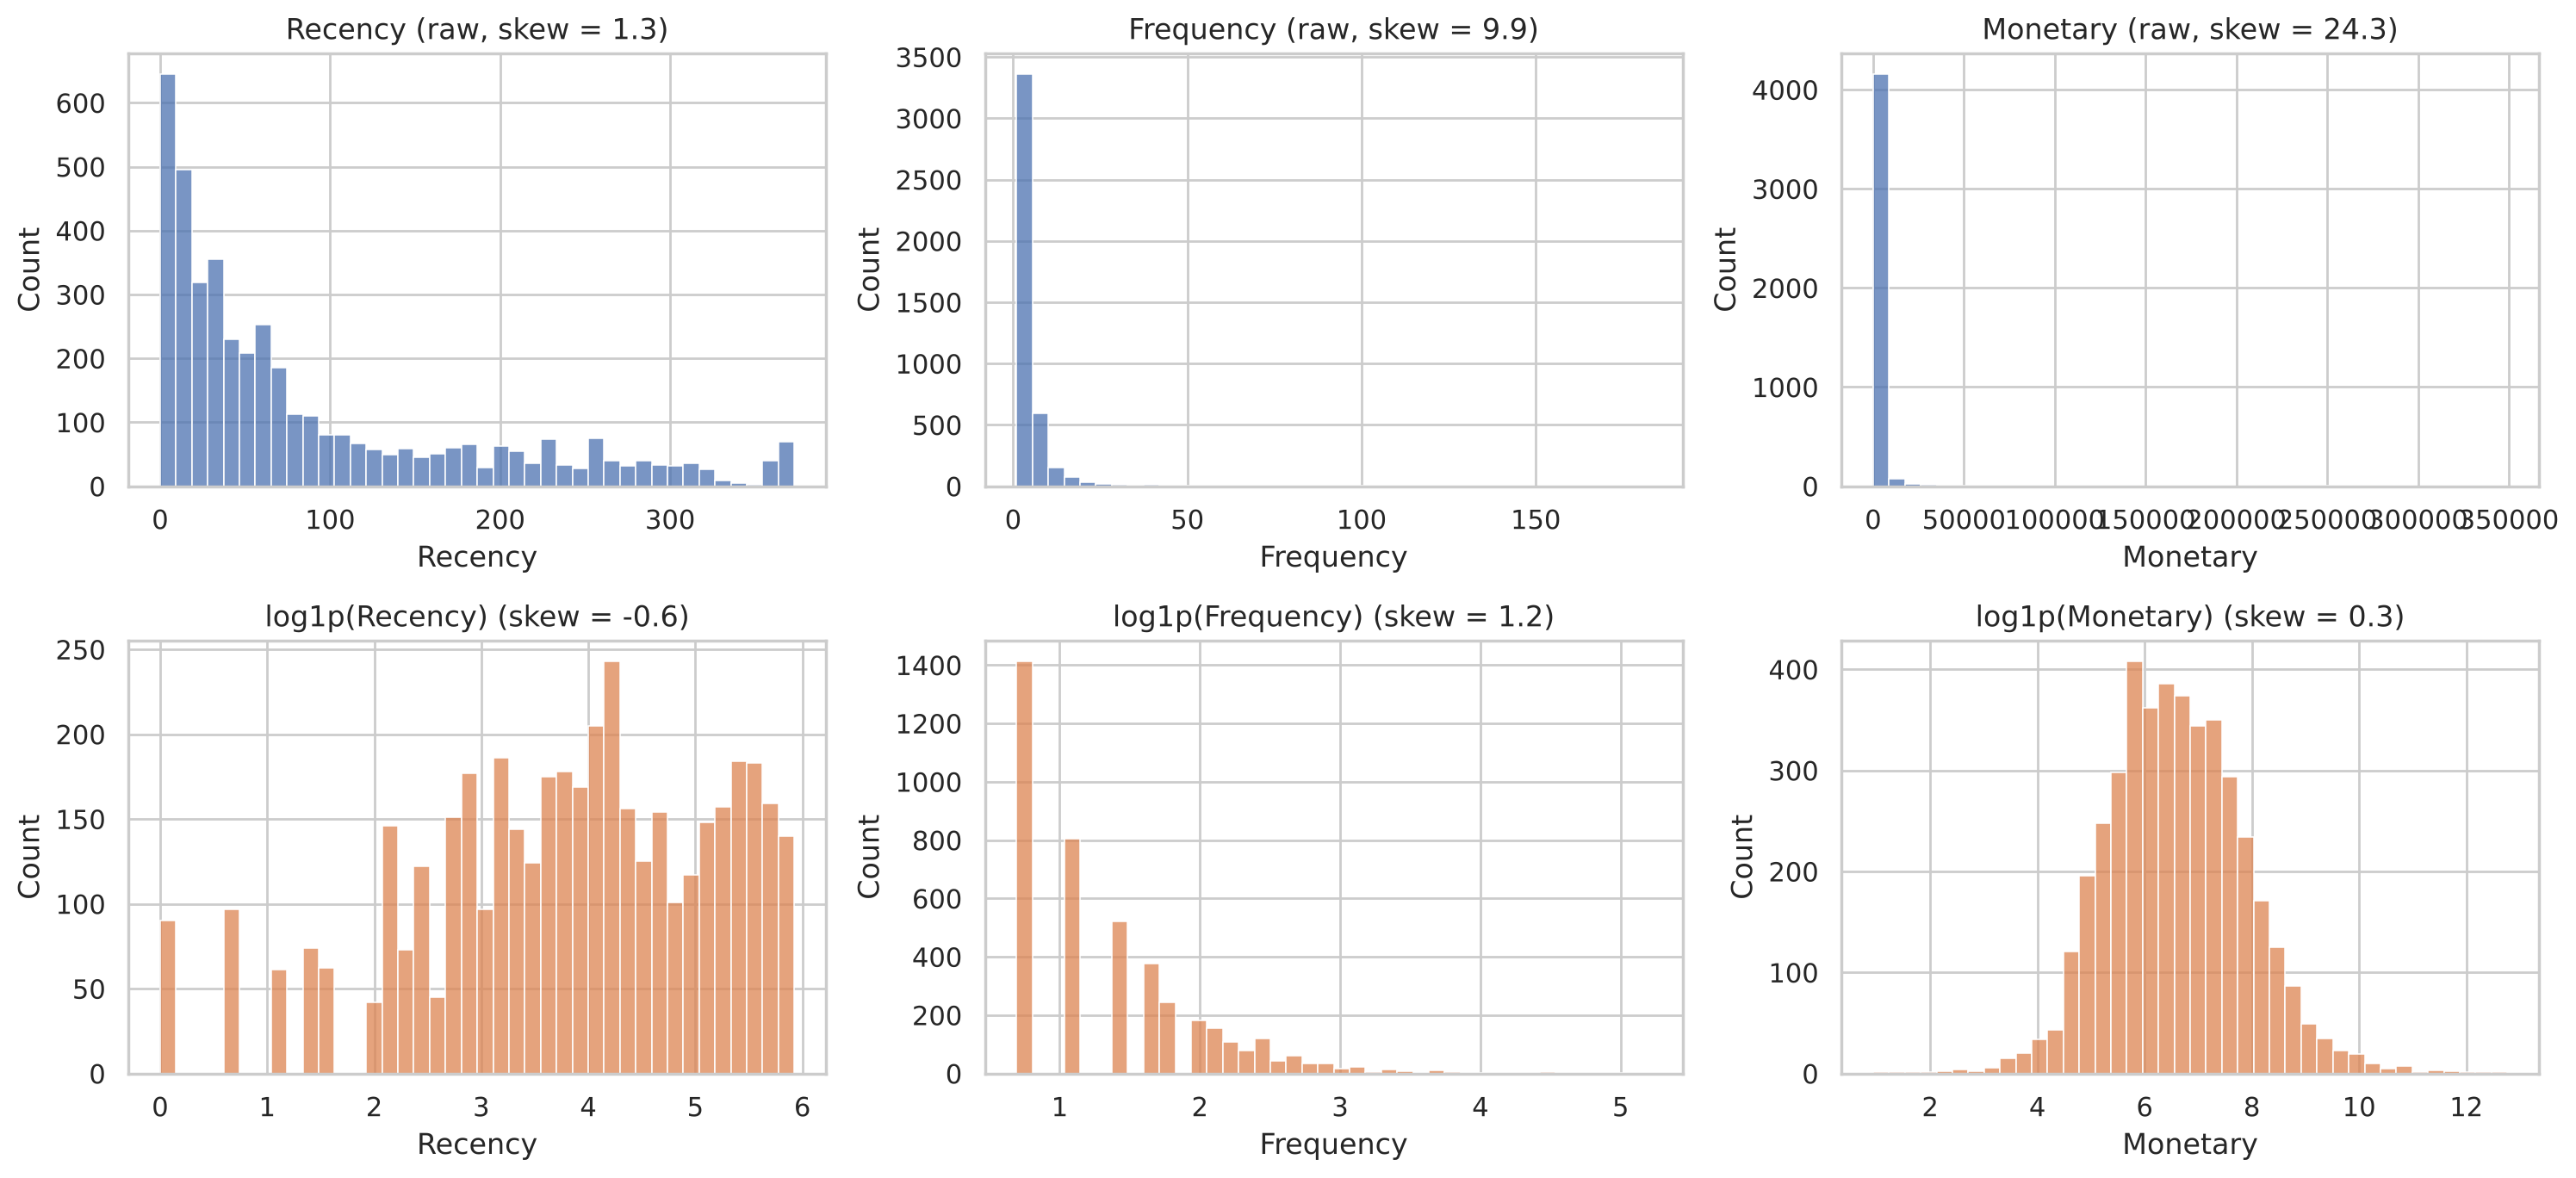

In [26]:
fig, ax = plt.subplots(2, 3, figsize=(15, 7))
for i, col in enumerate(rfm.columns):
    sns.histplot(rfm[col], bins=40, ax=ax[0, i]).set(title=f'{col} (raw, skew = {rfm[col].skew():.1f})')
    sns.histplot(np.log1p(rfm[col]), bins=40, ax=ax[1, i], color='C1').set(title=f'log1p({col}) (skew = {np.log1p(rfm[col]).skew():.1f})')
plt.tight_layout(); plt.show()

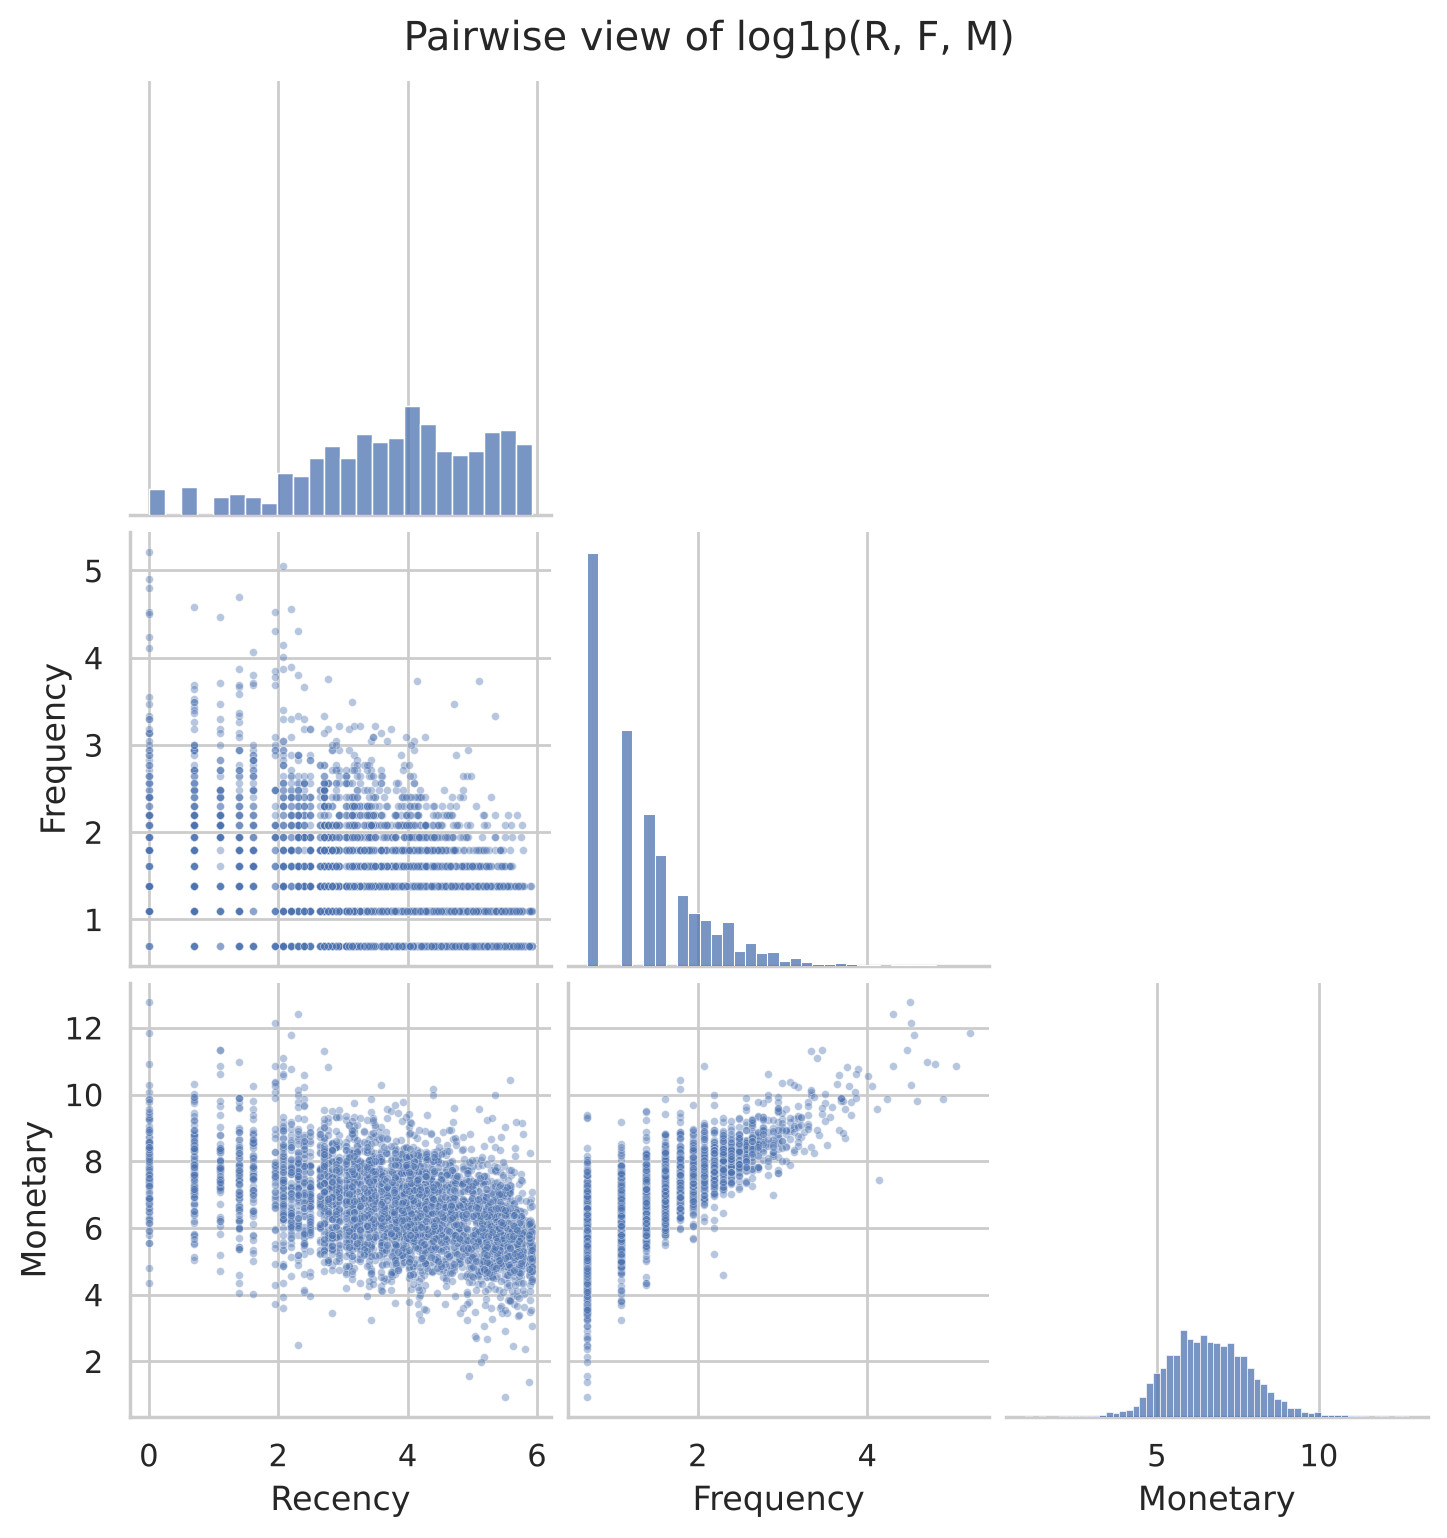

           Recency  Frequency  Monetary
Recency       1.00      -0.54     -0.46
Frequency    -0.54       1.00      0.82
Monetary     -0.46       0.82      1.00


In [27]:
g = sns.pairplot(np.log1p(rfm), corner=True, plot_kws={'s': 8, 'alpha': .4})
g.figure.suptitle('Pairwise view of log1p(R, F, M)', y=1.02); plt.show()
print(np.log1p(rfm).corr().round(2))

The raw RFM values are extremely right-skewed (a few customers spend hundreds of thousands), which would make K-Means spend all its clusters on those few. After `log1p` the shapes are much closer to normal. So the preprocessing is **log1p then standard scaling**. I keep the huge customers (they are real wholesale buyers, the VIPs I want to find) and let the log transform tame them instead of deleting them.

In [28]:
train_rfm, test_rfm = train_test_split(rfm, test_size=0.2, random_state=RANDOM_STATE)
print('train customers:', len(train_rfm), '| test customers:', len(test_rfm))

train customers: 3428 | test customers: 857


In [29]:
# Preprocessing pipeline: nothing needs encoding (all 3 features are numeric) and there are no missing values.
preprocessor = Pipeline([
    ('log', FunctionTransformer(np.log1p)),   # tames the skew / outliers
    ('scale', StandardScaler()),              # puts R, F, M on the same scale
])
X_train = preprocessor.fit_transform(train_rfm)   # fitted on TRAIN only
X_test = preprocessor.transform(test_rfm)         # only transformed
print('train mean ~', X_train.mean(axis=0).round(2), '| train std ~', X_train.std(axis=0).round(2))

train mean ~ [-0.  0. -0.] | train std ~ [1. 1. 1.]


# Modeling Pipeline

Step 1: choose the number of clusters **k** with the elbow method and silhouette score, using K-Means++ on the **train set only**.

I look at k = 2 to 10. k = 2 will almost always win silhouette on RFM data because it just splits "active" from "not active", which is too coarse to drive different marketing actions, so I choose k from **3 and above**.

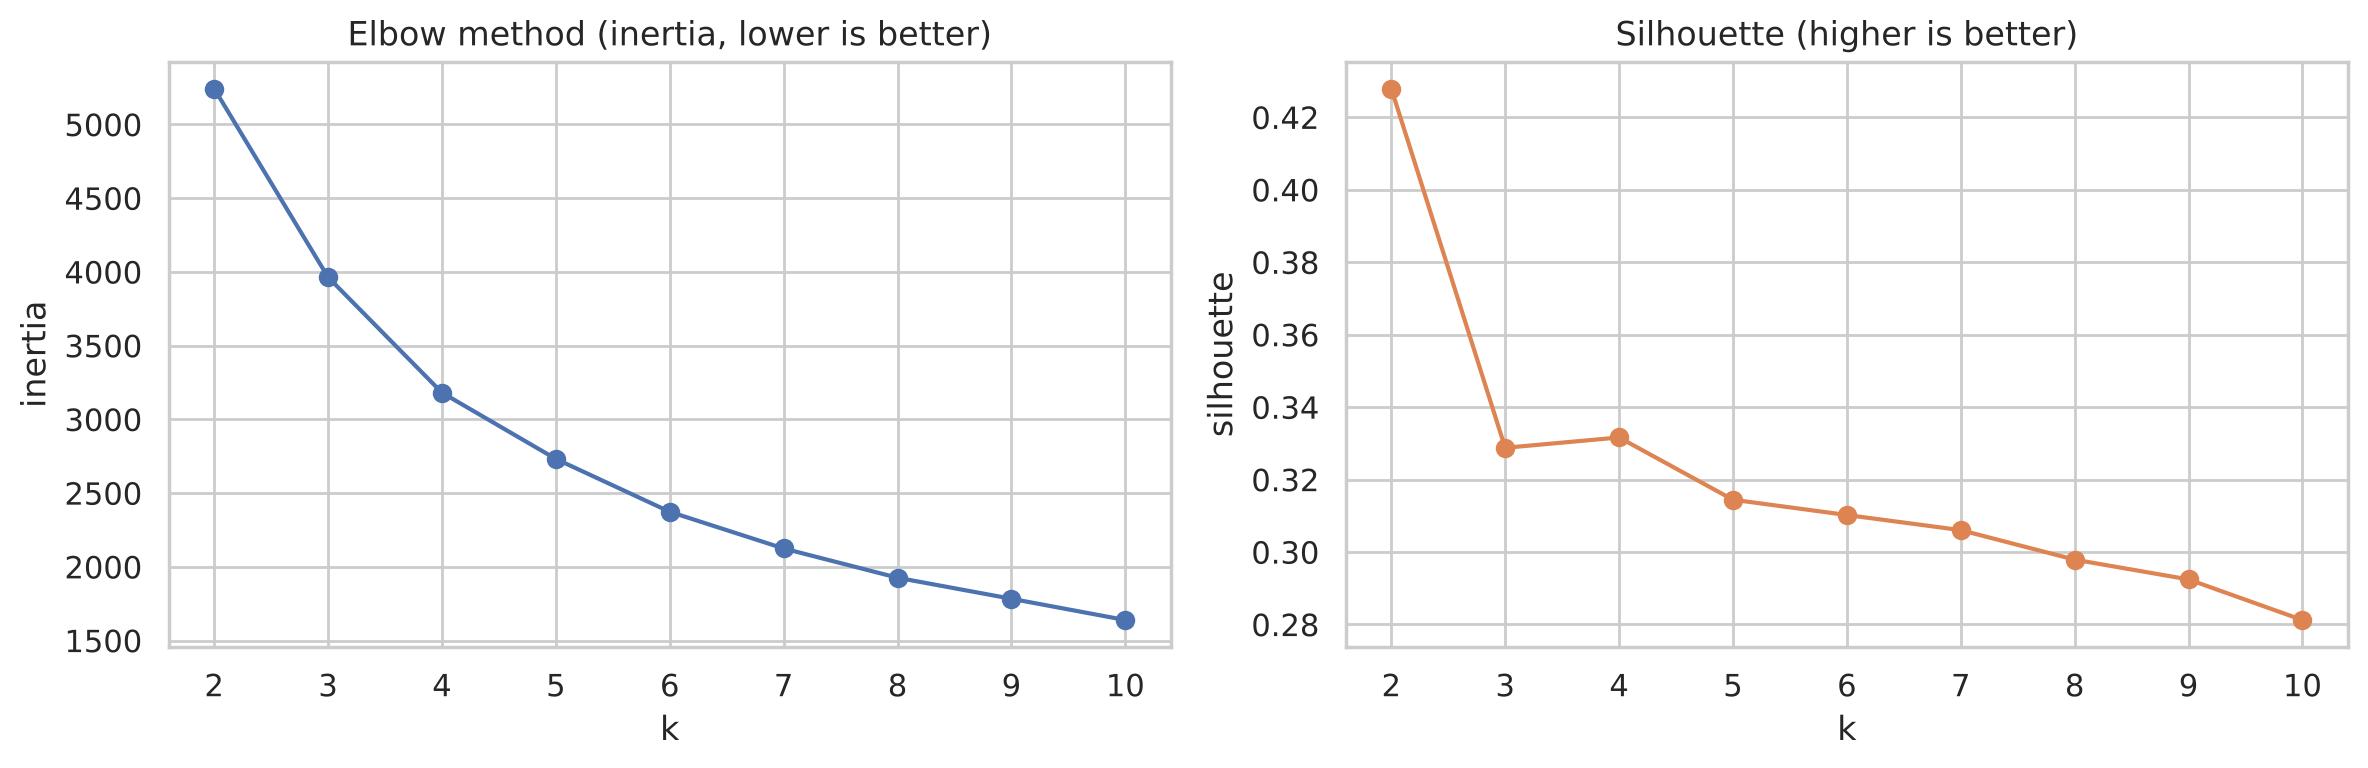

     inertia  silhouette  davies_bouldin
k                                       
2   5243.031       0.428           0.907
3   3964.075       0.329           1.069
4   3180.820       0.332           1.011
5   2731.452       0.314           1.051
6   2372.869       0.310           1.012
7   2124.079       0.306           0.975
8   1925.659       0.298           0.981
9   1782.994       0.292           1.005
10  1638.814       0.281           1.003

Chosen k (best silhouette for k >= 3): 4


In [30]:
rows = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=RANDOM_STATE).fit(X_train)
    rows.append({'k': k, 'inertia': km.inertia_,
                 'silhouette': silhouette_score(X_train, km.labels_),
                 'davies_bouldin': davies_bouldin_score(X_train, km.labels_)})
k_table = pd.DataFrame(rows).set_index('k')

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(k_table.index, k_table['inertia'], 'o-'); ax[0].set(title='Elbow method (inertia, lower is better)', xlabel='k', ylabel='inertia')
ax[1].plot(k_table.index, k_table['silhouette'], 'o-', color='C1'); ax[1].set(title='Silhouette (higher is better)', xlabel='k', ylabel='silhouette')
plt.tight_layout(); plt.show()

best_k = int(k_table.loc[3:, 'silhouette'].idxmax())      # best silhouette among k >= 3
print(k_table.round(3))
print('\nChosen k (best silhouette for k >= 3):', best_k)

In [31]:
# stability check: re-fit on bootstrap resamples and see if the same customers end up together (ARI = 1 means identical)
rng = np.random.RandomState(0)
stab = {}
for k in range(3, 9):
    base = KMeans(k, n_init=10, random_state=RANDOM_STATE).fit(X_train)
    ari = []
    for b in range(10):
        idx = rng.choice(len(X_train), len(X_train))
        other = KMeans(k, n_init=10, random_state=b).fit(X_train[idx])
        ari.append(adjusted_rand_score(base.labels_, other.predict(X_train)))
    stab[k] = np.mean(ari)
print('Stability (mean ARI over 10 bootstraps):'); print(pd.Series(stab).round(3).to_string())

Stability (mean ARI over 10 bootstraps):
3    0.879
4    0.922
5    0.765
6    0.842
7    0.804
8    0.804


Step 2: compare **three clustering algorithms** at the chosen k, against a simple **baseline** (random cluster labels, which should score about 0 on silhouette). All are fitted on the train set.

* **K-Means++**: clusters around mean centres.
* **K-Medoids**: like K-Means but centres are real customers (more robust to outliers). I wrote a short version of it myself so you do not need to install an extra library.
* **Hierarchical (Ward)**: builds a tree of merges; it cannot label new customers by itself, so for new customers I use the nearest cluster centre.

In [32]:
class KMedoids(BaseEstimator, ClusterMixin):
    """Small K-Medoids (Voronoi iteration, k-means++ style start)."""
    def __init__(self, n_clusters=4, max_iter=100, random_state=42):
        self.n_clusters = n_clusters; self.max_iter = max_iter; self.random_state = random_state

    def fit(self, X, y=None):
        X = np.asarray(X); rng = np.random.RandomState(self.random_state); D = pairwise_distances(X)
        med = [rng.randint(len(X))]
        for _ in range(self.n_clusters - 1):                       # spread-out starting medoids
            d = D[:, med].min(axis=1) ** 2
            med.append(rng.choice(len(X), p=d / d.sum()))
        med = np.array(med)
        for _ in range(self.max_iter):
            labels = D[:, med].argmin(axis=1); new = med.copy()
            for c in range(self.n_clusters):                       # medoid = member closest to all other members
                members = np.where(labels == c)[0]
                if len(members):
                    new[c] = members[D[np.ix_(members, members)].sum(axis=1).argmin()]
            if np.array_equal(new, med): break
            med = new
        self.medoid_indices_ = med; self.cluster_centers_ = X[med]; self.labels_ = D[:, med].argmin(axis=1)
        return self

    def predict(self, X):
        return pairwise_distances(np.asarray(X), self.cluster_centers_).argmin(axis=1)

In [33]:
def cluster_scores(X, labels):
    return {'Silhouette': silhouette_score(X, labels),
            'Davies-Bouldin': davies_bouldin_score(X, labels),
            'Calinski-Harabasz': calinski_harabasz_score(X, labels)}

fitted, train_labels = {}, {}

# baseline: random labels
train_labels['Baseline (random)'] = np.random.RandomState(RANDOM_STATE).randint(0, best_k, len(X_train))

# K-Means++
fitted['K-Means++'] = KMeans(best_k, init='k-means++', n_init=10, random_state=RANDOM_STATE).fit(X_train)
train_labels['K-Means++'] = fitted['K-Means++'].labels_

# K-Medoids
fitted['K-Medoids'] = KMedoids(best_k, random_state=RANDOM_STATE).fit(X_train)
train_labels['K-Medoids'] = fitted['K-Medoids'].labels_

# Hierarchical (Ward) + nearest-centroid so it can label unseen customers
ward = AgglomerativeClustering(n_clusters=best_k, linkage='ward').fit(X_train)
fitted['Hierarchical (Ward)'] = NearestCentroid().fit(X_train, ward.labels_)
train_labels['Hierarchical (Ward)'] = ward.labels_

train_scores = pd.DataFrame({name: cluster_scores(X_train, lab) for name, lab in train_labels.items()}).T
train_scores.round(3)

,Silhouette,Davies-Bouldin,Calinski-Harabasz
Baseline (random),-0.018,65.270,0.671
K-Means++,0.332,1.011,2548.775
K-Medoids,0.317,1.045,2435.179
Hierarchical (Ward),0.267,1.027,2011.075


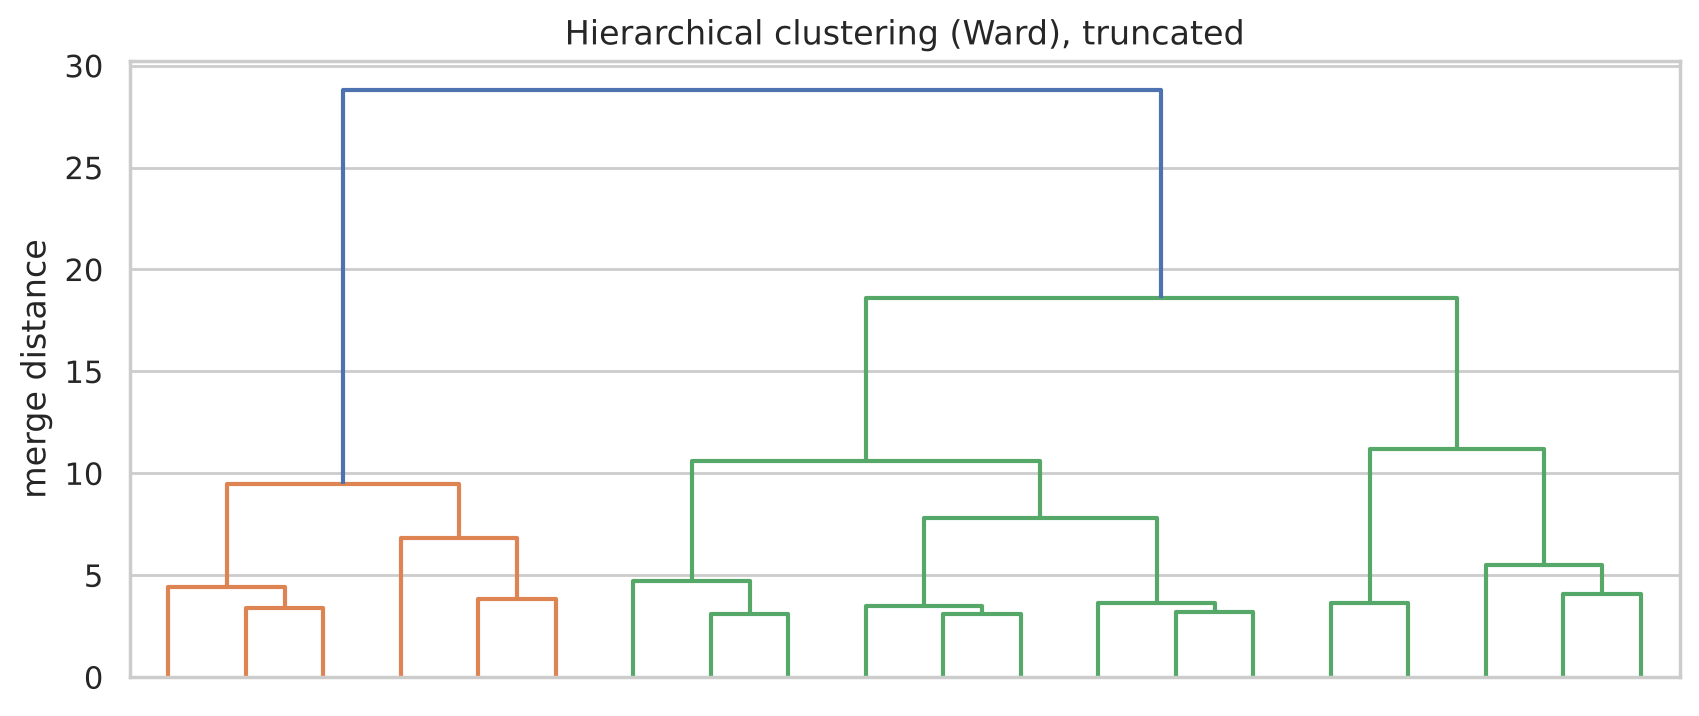

In [34]:
# dendrogram of the hierarchical method (on a 400-customer sample, last 20 merges only, to keep it readable)
sample = X_train[np.random.RandomState(RANDOM_STATE).choice(len(X_train), 400, replace=False)]
plt.figure(figsize=(10, 4))
dendrogram(linkage(sample, method='ward'), truncate_mode='lastp', p=20, no_labels=True)
plt.title('Hierarchical clustering (Ward), truncated'); plt.ylabel('merge distance'); plt.show()

**Which one to use?**


* **K-Means++ is the best of the three** on every train metric (silhouette 0.332 vs 0.317 for K-Medoids and 0.267 for Ward) and it is the simplest to explain and to reuse for new customers. All three are far better than the random baseline (silhouette about 0).
* **Choice of k:** the rule (best silhouette among k >= 3) picked **k = 4** on its own. It is also the most stable (bootstrap ARI about 0.92, higher than k = 3 and k = 5 to 8), and the elbow bends between 3 and 4. k = 3 is almost tied on silhouette but less stable; k >= 5 splits groups further but scores lower and is less stable. k = 2 scores best but is too coarse to act on.
* To try another k, change `best_k` in the cell above and re-run; everything after it follows.

# Evaluation Pipeline

Final scores on the **untouched test set**. The test customers were never used to choose k or to fit anything: they are only assigned to the clusters learned on train.

In [35]:
test_labels = {}
test_labels['Baseline (random)'] = np.random.RandomState(1).randint(0, best_k, len(X_test))
for name, model in fitted.items():
    test_labels[name] = model.predict(X_test)

test_scores = pd.DataFrame({name: cluster_scores(X_test, lab) for name, lab in test_labels.items()}).T
print('TEST set scores'); display(test_scores.round(3))
print('Train vs test silhouette for the chosen model (K-Means++):',
      round(train_scores.loc['K-Means++', 'Silhouette'], 3), '->', round(test_scores.loc['K-Means++', 'Silhouette'], 3))

TEST set scores


,Silhouette,Davies-Bouldin,Calinski-Harabasz
Baseline (random),-0.038,28.419,0.851
K-Means++,0.316,1.050,606.373
K-Medoids,0.312,1.047,603.930
Hierarchical (Ward),0.303,1.020,561.834


Train vs test silhouette for the chosen model (K-Means++): 0.332 -> 0.316


Visual check: PCA squeezes the 3 scaled features into 2 axes so the clusters can be drawn.

Variance explained by the 2 PCA axes: 0.942


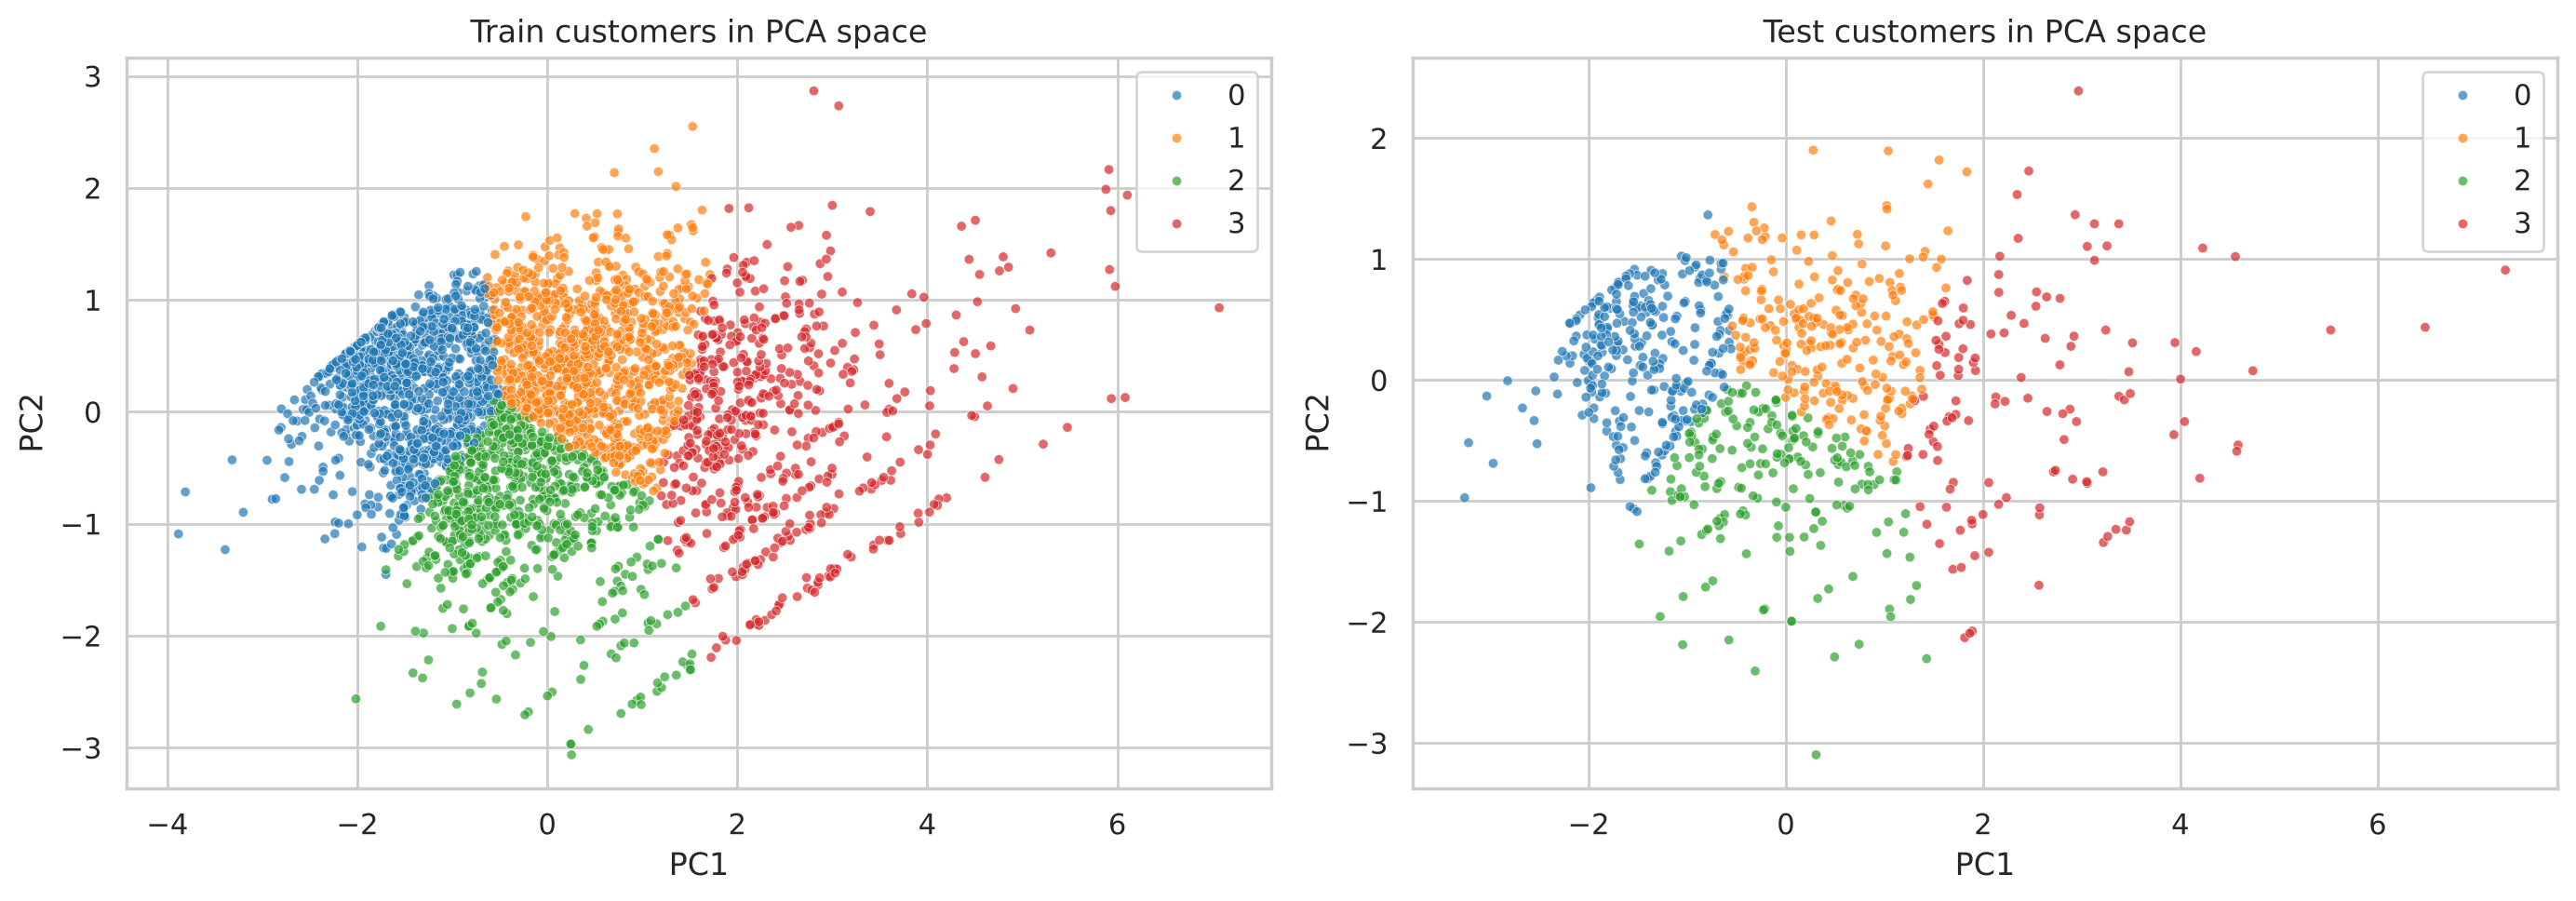

In [36]:
final_km = fitted['K-Means++']
pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(X_train)
print('Variance explained by the 2 PCA axes:', pca.explained_variance_ratio_.sum().round(3))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for a, X_, lab, title in [(ax[0], X_train, final_km.labels_, 'Train'), (ax[1], X_test, final_km.predict(X_test), 'Test')]:
    p = pca.transform(X_)
    sns.scatterplot(x=p[:, 0], y=p[:, 1], hue=lab, palette='tab10', s=14, alpha=.7, ax=a)
    a.set(title=f'{title} customers in PCA space', xlabel='PC1', ylabel='PC2')
plt.tight_layout(); plt.show()

### What does each cluster look like in real units (days, orders, GBP)?

In [37]:
# label every customer with the model that was fitted on train
all_labels = pd.Series(final_km.predict(preprocessor.transform(rfm)), index=rfm.index, name='cluster')
seg = rfm.assign(cluster=all_labels)

profile = seg.groupby('cluster').agg(customers=('Recency', 'size'),
                                     median_recency_days=('Recency', 'median'),
                                     median_orders=('Frequency', 'median'),
                                     median_spend=('Monetary', 'median'),
                                     mean_recency_days=('Recency', 'mean'),
                                     mean_orders=('Frequency', 'mean'),
                                     mean_spend=('Monetary', 'mean'),
                                     total_spend=('Monetary', 'sum'))
profile['% customers'] = profile['customers'] / profile['customers'].sum() * 100
profile['% revenue'] = profile['total_spend'] / profile['total_spend'].sum() * 100
profile = profile.sort_values('median_spend', ascending=False)
profile.round(1)

,customers,median_recency_days,median_orders,median_spend,mean_recency_days,mean_orders,mean_spend,total_spend,% customers,% revenue
cluster,,,,,,,,,,
3,707,8.0,10.0,3641.0,11.5,14.0,7689.0,5436119.8,16.5,62.9
1,1250,57.0,4.0,1389.7,73.5,4.3,1824.2,2280226.0,29.2,26.4
2,909,20.0,2.0,450.8,22.6,1.9,518.5,471281.4,21.2,5.5
0,1419,181.0,1.0,267.9,185.4,1.3,318.5,452015.2,33.1,5.2


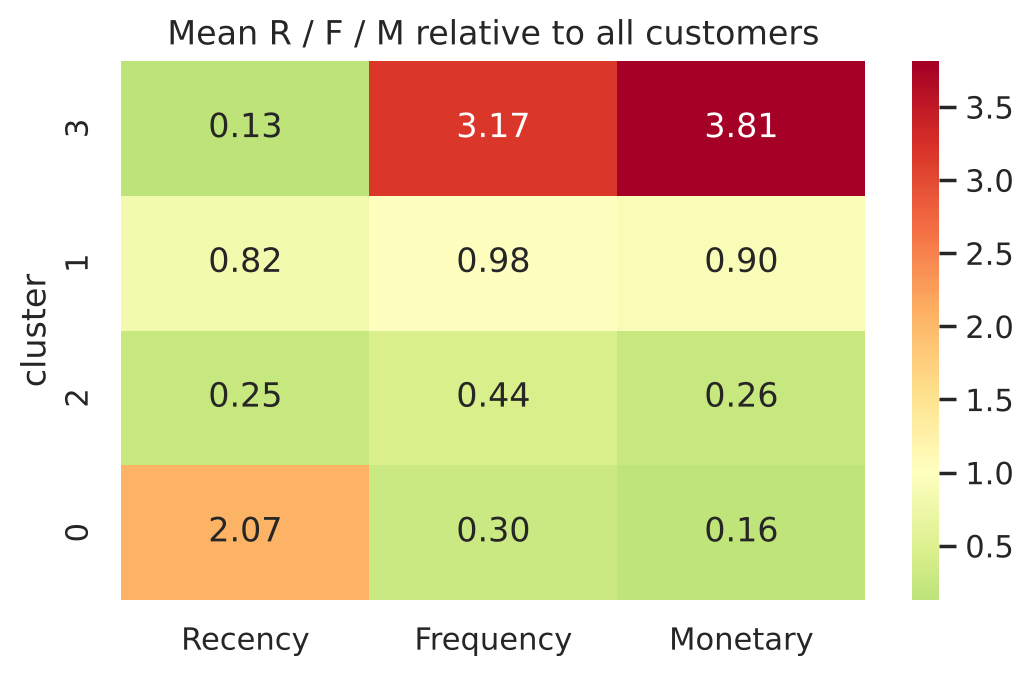

In [38]:
# heatmap: how far is each cluster from the average customer (1.0 = average)
rel = seg.groupby('cluster')[['Recency', 'Frequency', 'Monetary']].mean() / rfm.mean()
plt.figure(figsize=(6, 3.5))
sns.heatmap(rel.loc[profile.index], annot=True, fmt='.2f', cmap='RdYlGn_r', center=1)
plt.title('Mean R / F / M relative to all customers'); plt.show()

### Error analysis: which customers are badly assigned?

Customers with negative silhouette (closer to another cluster than to their own):


,mean_silhouette,share_badly_assigned
cluster,,
0,0.421,0.000
1,0.313,0.009
2,0.253,0.033
3,0.287,0.080


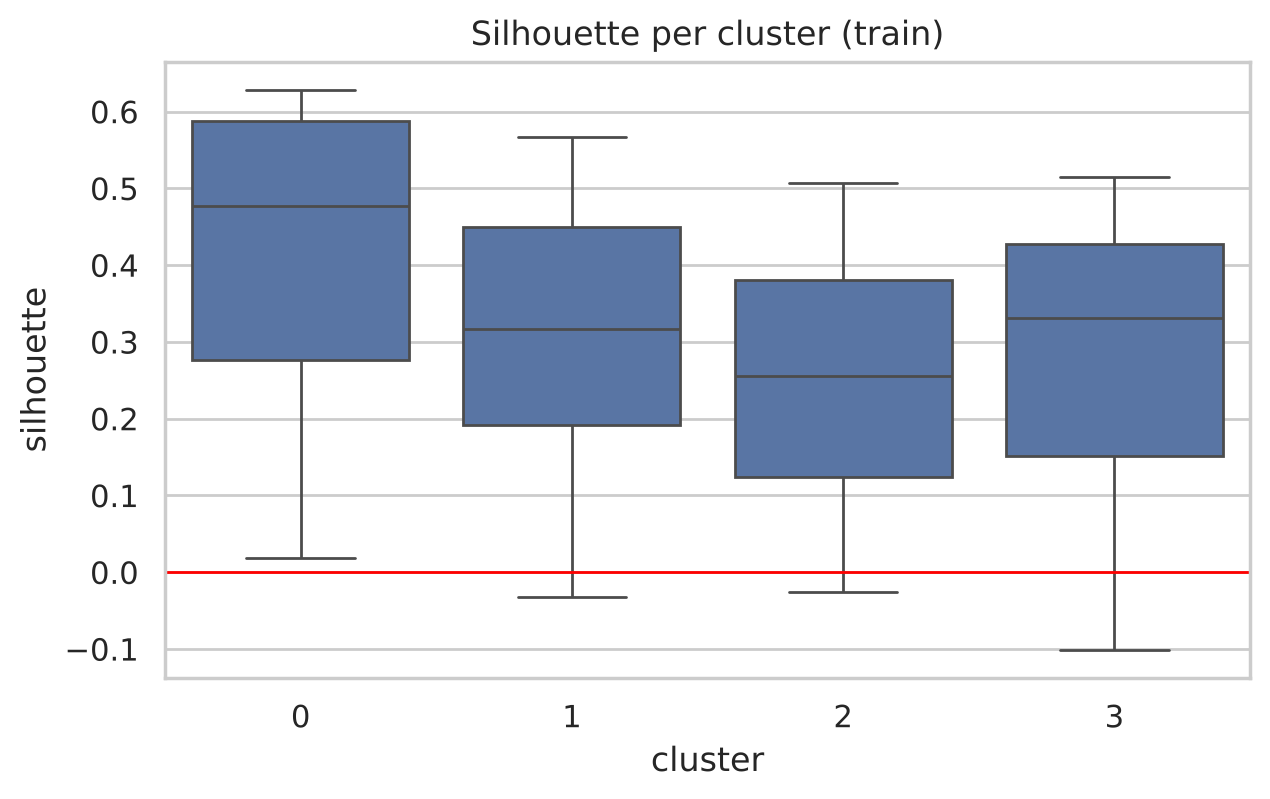

Examples of the most ambiguous customers (real R / F / M):


,Recency,Frequency,Monetary,cluster
Customer ID,,,,
15173,15,7,1494.60,3
13037,34,9,3033.88,3
15034,21,6,3957.04,3
12417,45,11,2772.31,3
17150,11,6,1357.95,3


In [39]:
sil = silhouette_samples(X_train, final_km.labels_)
err = pd.DataFrame({'cluster': final_km.labels_, 'silhouette': sil}, index=train_rfm.index)
by_cluster = err.groupby('cluster')['silhouette'].agg(mean_silhouette='mean',
                                                      share_badly_assigned=lambda s: (s < 0).mean())
print('Customers with negative silhouette (closer to another cluster than to their own):')
display(by_cluster.round(3))

fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=err, x='cluster', y='silhouette', ax=ax); ax.axhline(0, color='red', lw=1)
ax.set(title='Silhouette per cluster (train)'); plt.show()

print('Examples of the most ambiguous customers (real R / F / M):')
display(train_rfm.loc[err.nsmallest(5, 'silhouette').index].assign(cluster=err['silhouette'].nsmallest(5).index.map(err['cluster'])))

**Reading the error analysis:** the weakest points are customers sitting on the border between two neighbouring groups (for example a customer who bought a few months ago with medium spend). That is normal for RFM data, which is a smooth continuum, not separate islands. These customers are the ones whose segment can flip with small changes, so marketing should not treat the borders as hard walls.

# Hyper ParameterTuning

Grid search with 5-fold cross-validation **on the training customers only**. The whole pipeline (log, scaling, K-Means) is refitted inside every fold, and the score is the silhouette on the held-out fold. I search k from 3 to 8 and the K-Means initialisation method.

In [40]:
def cv_silhouette(estimator, X, y=None):
    """Silhouette of the held-out fold, using the scaler and clusters learned on the other folds."""
    return silhouette_score(estimator[:-1].transform(X), estimator.predict(X))

search_pipe = Pipeline([
    ('log', FunctionTransformer(np.log1p)),
    ('scale', StandardScaler()),
    ('kmeans', KMeans(n_init=10, random_state=RANDOM_STATE)),
])
grid = GridSearchCV(search_pipe,
                    param_grid={'kmeans__n_clusters': [3, 4, 5, 6, 7, 8],
                                'kmeans__init': ['k-means++', 'random']},
                    scoring=cv_silhouette, cv=KFold(5, shuffle=True, random_state=RANDOM_STATE), refit=True)
grid.fit(train_rfm)

cv = pd.DataFrame(grid.cv_results_)[['param_kmeans__n_clusters', 'param_kmeans__init', 'mean_test_score', 'std_test_score']]
cv.columns = ['k', 'init', 'cv_silhouette', 'std']
display(cv.sort_values('cv_silhouette', ascending=False).head(6).round(3))
print('Best params:', grid.best_params_, '| CV silhouette:', round(grid.best_score_, 3))

,k,init,cv_silhouette,std
1,4,k-means++,0.330,0.009
7,4,random,0.330,0.009
0,3,k-means++,0.328,0.010
6,3,random,0.327,0.009
8,5,random,0.311,0.007
2,5,k-means++,0.311,0.007


Best params: {'kmeans__init': 'k-means++', 'kmeans__n_clusters': 4} | CV silhouette: 0.33


In [41]:
# final pipeline = best CV model (already refitted on the full train set by GridSearchCV)
final_pipe = grid.best_estimator_

test_final = cluster_scores(final_pipe[:-1].transform(test_rfm), final_pipe.predict(test_rfm))
print('FINAL test scores:', {k: round(v, 3) for k, v in test_final.items()})
print('Same k and similar score as before tuning?  k =', final_pipe['kmeans'].n_clusters,
      '| silhouette before tuning (test):', round(test_scores.loc['K-Means++', 'Silhouette'], 3))

FINAL test scores: {'Silhouette': 0.316, 'Davies-Bouldin': 1.05, 'Calinski-Harabasz': 606.373}
Same k and similar score as before tuning?  k = 4 | silhouette before tuning (test): 0.316


Tuning confirms the choice: the best k found by cross-validation is the same k picked earlier, and the initialisation method barely matters (K-Means++ and random starts score almost the same because the data has only 3 dimensions). I only tuned the selected algorithm because the other two scored lower in the comparison.

# Saving Pipelines and Models

Save everything the app will need later: the full pipeline (log + scaling + clusters), the preprocessing part alone, and the segment profiles.

In [42]:
# refresh the customer segments with the FINAL pipeline
seg = rfm.assign(cluster=final_pipe.predict(rfm))

joblib.dump(final_pipe, 'segmentation_pipeline.joblib')          # raw RFM -> cluster id
joblib.dump(final_pipe[:-1], 'rfm_preprocessor.joblib')          # raw RFM -> scaled features
seg.to_csv('customer_segments.csv')                              # customer id -> R, F, M, cluster

segment_profile = seg.groupby('cluster').agg(customers=('Recency', 'size'),
                                             median_recency_days=('Recency', 'median'),
                                             median_orders=('Frequency', 'median'),
                                             median_spend=('Monetary', 'median'),
                                             total_spend=('Monetary', 'sum'))
segment_profile['% revenue'] = segment_profile['total_spend'] / segment_profile['total_spend'].sum() * 100
segment_profile.to_csv('segment_profiles.csv')

with open('model_info.json', 'w') as f:
    json.dump({'snapshot_date': str(snapshot_date.date()), 'features': ['Recency', 'Frequency', 'Monetary'],
               'n_clusters': int(final_pipe['kmeans'].n_clusters), 'random_state': RANDOM_STATE,
               'cleaning_and_rfm_code': 'rfm_utils.py'}, f, indent=2)
print('saved: segmentation_pipeline.joblib, rfm_preprocessor.joblib, customer_segments.csv, segment_profiles.csv, model_info.json')

saved: segmentation_pipeline.joblib, rfm_preprocessor.joblib, customer_segments.csv, segment_profiles.csv, model_info.json


In [43]:
# reusability test: load the pipeline in a "fresh" way and score 3 customers from their raw R/F/M
loaded = joblib.load('segmentation_pipeline.joblib')
demo = rfm.sample(3, random_state=1)
print(demo.assign(cluster=loaded.predict(demo)))
assert (loaded.predict(rfm) == seg['cluster'].values).all(), 'loaded pipeline gives different clusters!'
print('OK: the saved pipeline reproduces every customer\'s cluster')

             Recency  Frequency  Monetary  cluster
Customer ID                                       
14843             71          1    211.80        0
13646             34          2    326.25        2
17132             87          2   1220.91        1
OK: the saved pipeline reproduces every customer's cluster


# Business Insights

# Business Insights

*(Numbers below come from the run in this notebook, segment ids may be numbered differently on another machine, so segments are described by their behaviour. Medians are used because spend is very skewed.)*

The model found **4 customer groups** out of 4,285 customers. Each row is one group, sorted from most to least valuable:

| Group (behaviour) | Customers | Recency (median) | Orders (median) | Spend (median) | Share of revenue |
|---|---|---|---|---|---|
| **A. Frequent, recent, high spenders** | 707 (16.5%) | 8 days | 10 | GBP 3,641 | **62.9%** |
| **B. Regular mid-spenders, starting to cool down** | 1,250 (29.2%) | 57 days | 4 | GBP 1,390 | 26.4% |
| **C. Recent buyers with few orders** | 909 (21.2%) | 20 days | 2 | GBP 451 | 5.5% |
| **D. Long-gone, one-time buyers** | 1,419 (33.1%) | 181 days | 1 | GBP 268 | 5.2% |

**In plain language**

* Group A is only one customer in six but brings almost two thirds of the revenue. Losing a few of them costs more than losing all of group D.
* Group B is the biggest opportunity: they have bought repeatedly but have not ordered for about two months.
* Group C looks like newer customers: they bought recently but have not come back much yet.
* Group D bought once, long ago, and generates about 5% of revenue.

**What to do next:** decide a marketing action for each group (the actions for the app, as planned) and then build the 90-day spend regression, so that the revenue at stake in each group can be estimated.

**Quality of the result:** test silhouette is 0.32 (train 0.33) and Davies-Bouldin is about 1.05, so the groups are real but **not sharply separated**: RFM behaviour is a continuum and customers near a border can switch groups. The segments are stable, though (bootstrap ARI about 0.92).

**Limitations**
* Only one year of data, so seasonality (the Nov peak) cannot be separated from real behaviour change; a customer last seen in July looks "inactive" even if they only buy for Christmas.
* Cancellations and returns were removed, not subtracted, so spend is gross, not net.
* The data comes from a retailer that also sells to wholesalers; very large buyers are in group A and are not a "typical" customer.
* Only R, F and M are used: product mix, country and discounts are ignored.
* Customers appearing in the data without an ID (about 20% of rows) cannot be segmented at all.
* The segmentation uses a fixed snapshot date (10 Dec 2010); for live use it must be recomputed regularly.

# Part 2: 90-Day Spend Prediction (Regression)

## 1. Problem framing

* **Decision:** how much money each customer is expected to bring in the next 3 months, so marketing can size the revenue at stake in every segment and decide where to spend.
* **Target:** `spend_next_90d` = what the customer actually spends in the 90 days **after a cut-off date** (0 if they do not buy).
* **Metric that matters:** **MAE** in GBP (the average error per customer, easy for a manager to understand). I also report RMSE and R². I do not use R² alone because a few huge customers dominate it.
* **No leakage:** all features are built only from orders **before** the cut-off, and the target only from orders **after** it.

In [44]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## 2. Target and features with a time cut-off

The data ends on 9 Dec 2010. The cut-off is 90 days before that. Features (R, F, M) are computed from the cleaned orders before the cut-off, the target from the orders after it.

In [45]:
data_end = clean['InvoiceDate'].max().normalize() + pd.Timedelta(days=1)
cutoff = data_end - pd.Timedelta(days=90)
print('cut-off date:', cutoff.date(), '| data ends:', data_end.date())

past = clean[clean['InvoiceDate'] < cutoff]       # used for features
future = clean[clean['InvoiceDate'] >= cutoff]    # used for the target only

X_all, _ = build_rfm(past, cutoff)                # same R, F, M definition as the segmentation
y_all = future.groupby('Customer ID')['Spend'].sum().reindex(X_all.index).fillna(0)   # 0 = did not buy

print('customers with history before the cut-off:', len(X_all))
print(f'share who bought nothing in the next 90 days: {(y_all == 0).mean():.0%}')
y_all.describe().round(0)

cut-off date: 2010-09-11 | data ends: 2010-12-10


customers with history before the cut-off: 3355
share who bought nothing in the next 90 days: 42%


count     3355.0
mean       737.0
std       2950.0
min          0.0
25%          0.0
50%        207.0
75%        690.0
max      80123.0
Name: Spend, dtype: float64

### Quick EDA of the target

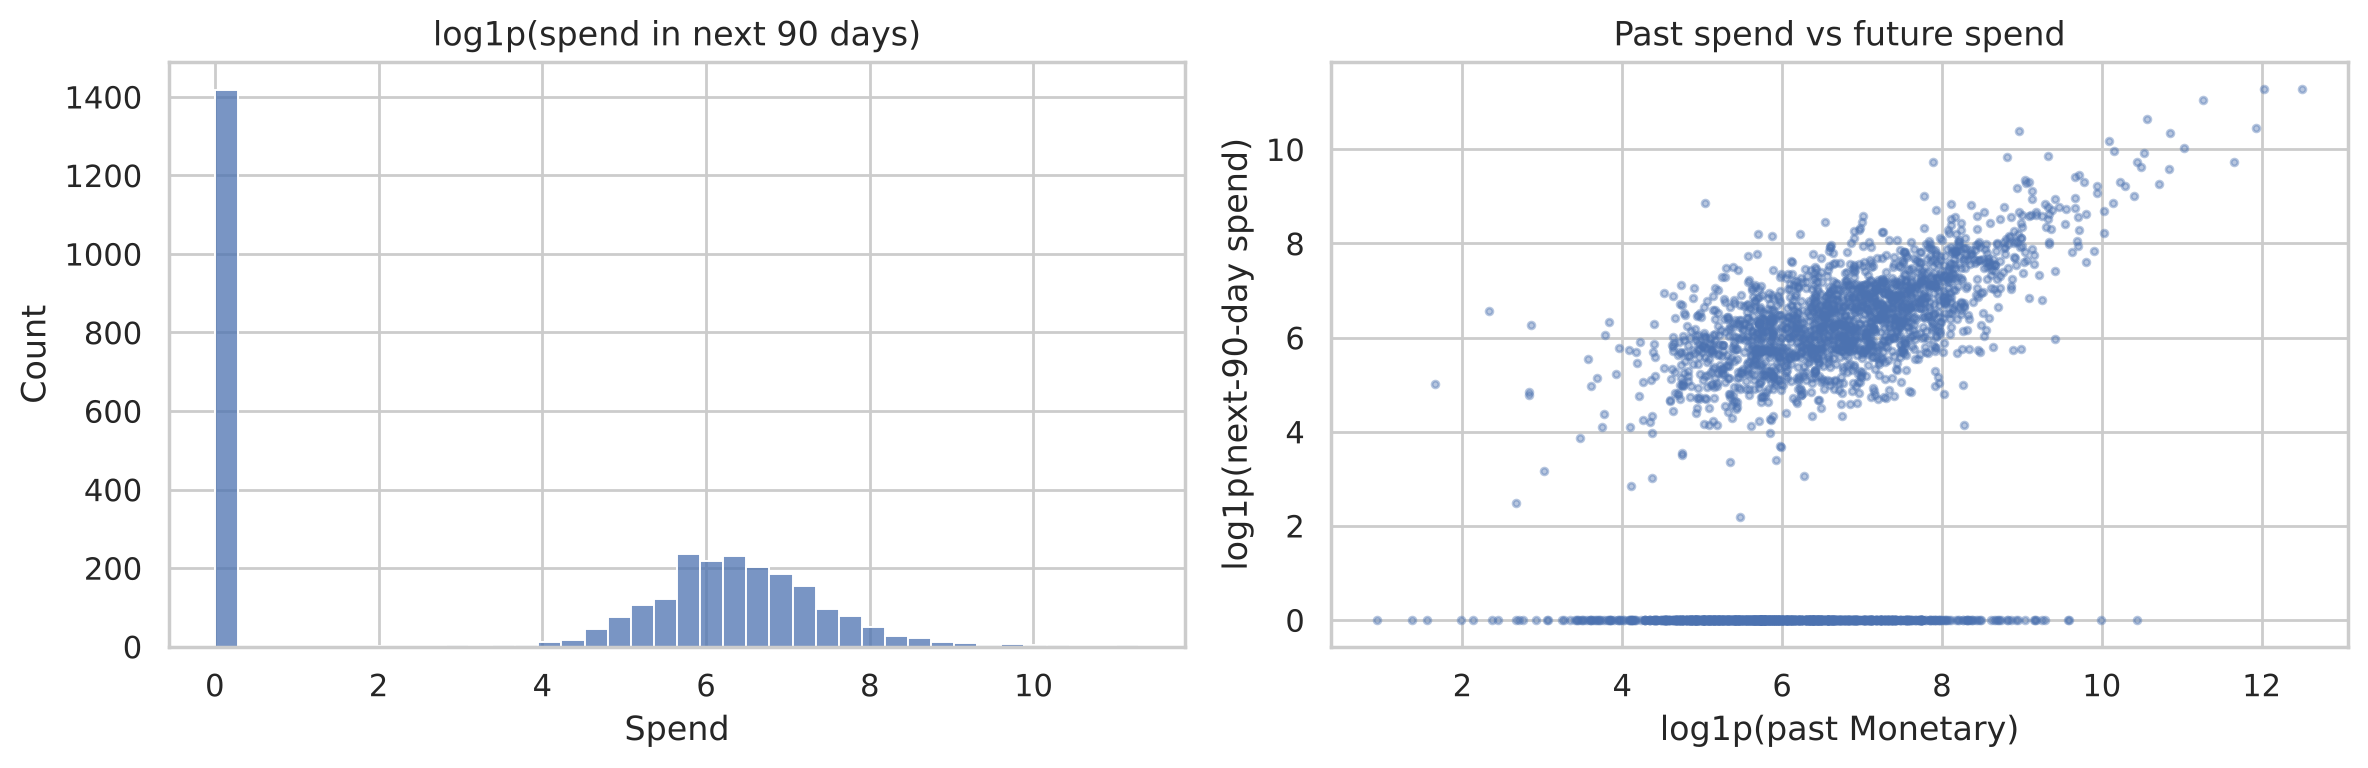

Recency     -0.28
Frequency    0.45
Monetary     0.46
Name: spend_next_90d, dtype: float64


In [46]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(np.log1p(y_all), bins=40, ax=ax[0]).set(title='log1p(spend in next 90 days)')
ax[1].scatter(np.log1p(X_all['Monetary']), np.log1p(y_all), s=6, alpha=.4)
ax[1].set(xlabel='log1p(past Monetary)', ylabel='log1p(next-90-day spend)', title='Past spend vs future spend')
plt.tight_layout(); plt.show()
print(pd.concat([np.log1p(X_all), np.log1p(y_all).rename('spend_next_90d')], axis=1).corr()['spend_next_90d'].round(2).drop('spend_next_90d'))

* About 4 in 10 customers buy nothing in the next 90 days, so the target has a big spike at 0 and a long tail.
* Past spend and past frequency are clearly related to future spend, and recency is negatively related: customers who bought recently buy again.

## 3. Split and preprocessing pipeline (split first)

In [47]:
Xr_train, Xr_test, yr_train, yr_test = train_test_split(X_all, y_all, test_size=0.2, random_state=RANDOM_STATE)
print('train:', len(Xr_train), '| test:', len(Xr_test))

def make_pipe(model):
    # same preprocessing as the segmentation: log1p (skew) + scaling, then the model
    return Pipeline([('log', FunctionTransformer(np.log1p)), ('scale', StandardScaler()), ('model', model)])

train: 2684 | test: 671


## 4. Modeling: baseline + 3 algorithms

* **Baseline:** always predict the average spend.
* **Ridge (linear regression):** simple and easy to explain.
* **Random Forest** and **Gradient Boosting:** tree models that can capture non-linear behaviour.

Compared with 5-fold cross-validation **on the train set only** (MAE, lower is better).

In [48]:
candidates = {
    'Baseline (mean)': DummyRegressor(strategy='mean'),
    'Ridge': Ridge(),
    'Random Forest': RandomForestRegressor(n_estimators=200, min_samples_leaf=5, random_state=RANDOM_STATE, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(random_state=RANDOM_STATE),
}
cv_rows = {}
for name, model in candidates.items():
    mae = -cross_val_score(make_pipe(model), Xr_train, yr_train, cv=5, scoring='neg_mean_absolute_error')
    rmse = -cross_val_score(make_pipe(model), Xr_train, yr_train, cv=5, scoring='neg_root_mean_squared_error')
    r2 = cross_val_score(make_pipe(model), Xr_train, yr_train, cv=5, scoring='r2')
    cv_rows[name] = {'CV MAE': mae.mean(), 'CV RMSE': rmse.mean(), 'CV R2': r2.mean()}
pd.DataFrame(cv_rows).T.round(2)

,CV MAE,CV RMSE,CV R2
Baseline (mean),762.40,1997.59,-0.01
Ridge,756.62,1794.47,0.17
Random Forest,539.52,1489.82,0.30
Gradient Boosting,546.75,1641.69,0.25


**Which model?** The two tree models are far better than the baseline and Ridge, and **Random Forest has the best cross-validated MAE, RMSE and R²**, so it is the one I tune. The choice is made on the cross-validation scores of the train set only, not on the test set.

## 5. Hyperparameter tuning (cross-validation on train only)

In [49]:
grid = GridSearchCV(make_pipe(RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1)),
                    param_grid={'model__n_estimators': [200, 400],
                                'model__max_depth': [5, 8, None],
                                'model__min_samples_leaf': [3, 5, 10, 20]},
                    scoring='neg_mean_absolute_error', cv=5)
grid.fit(Xr_train, yr_train)
print('Best params:', grid.best_params_)
print('CV MAE: before tuning', round(cv_rows['Random Forest']['CV MAE'], 1), '-> after tuning', round(-grid.best_score_, 1))
spend_pipe = grid.best_estimator_      # refitted on the full train set

Best params: {'model__max_depth': 5, 'model__min_samples_leaf': 5, 'model__n_estimators': 400}
CV MAE: before tuning 539.5 -> after tuning 526.8


## 6. Evaluation on the untouched test set

In [50]:
def reg_scores(y_true, y_pred):
    return {'MAE (GBP)': mean_absolute_error(y_true, y_pred),
            'RMSE (GBP)': mean_squared_error(y_true, y_pred) ** 0.5,
            'R2': r2_score(y_true, y_pred)}

test_rows = {}
for name, model in candidates.items():
    test_rows[name] = reg_scores(yr_test, make_pipe(model).fit(Xr_train, yr_train).predict(Xr_test))
pred_test = spend_pipe.predict(Xr_test)
test_rows['Random Forest (tuned) = FINAL'] = reg_scores(yr_test, pred_test)
pd.DataFrame(test_rows).T.round(2)

,MAE (GBP),RMSE (GBP),R2
Baseline (mean),1138.99,5091.67,-0.01
Ridge,1059.98,4716.40,0.14
Random Forest,759.38,3477.42,0.53
Gradient Boosting,740.62,3182.74,0.61
Random Forest (tuned) = FINAL,741.00,3473.38,0.53


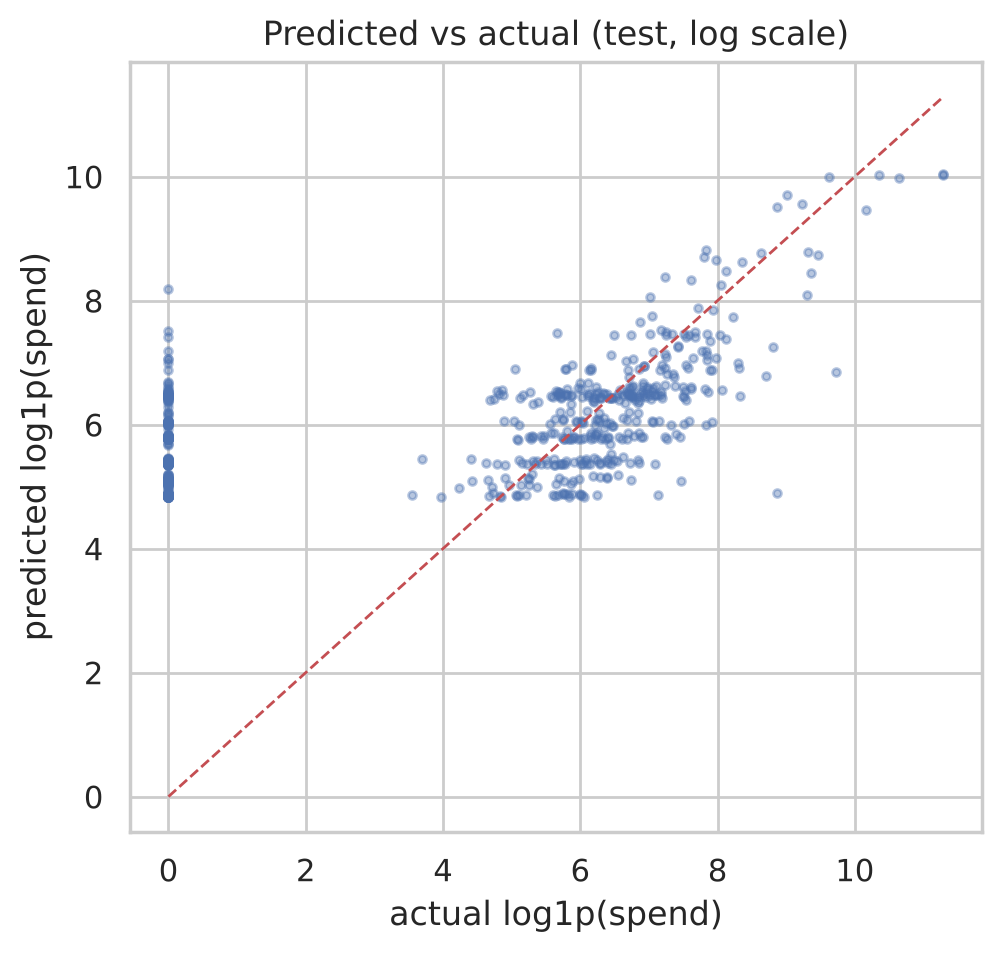

In [51]:
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(np.log1p(yr_test), np.log1p(np.clip(pred_test, 0, None)), s=8, alpha=.4)
lim = [0, np.log1p(yr_test.max())]; ax.plot(lim, lim, 'r--', lw=1)
ax.set(xlabel='actual log1p(spend)', ylabel='predicted log1p(spend)', title='Predicted vs actual (test, log scale)')
plt.show()

### Error analysis

In [52]:
err = pd.DataFrame({'actual': yr_test, 'pred': pred_test})
err['abs_error'] = (err['actual'] - err['pred']).abs()
err['bucket'] = pd.cut(err['actual'], [-1, 0, 200, 1000, 5000, np.inf],
                       labels=['bought nothing', '1-200', '200-1,000', '1,000-5,000', '5,000+'])
by_bucket = err.groupby('bucket', observed=True).agg(customers=('actual', 'size'), mean_actual=('actual', 'mean'),
                                                     mean_predicted=('pred', 'mean'), MAE=('abs_error', 'mean'))
display(by_bucket.round(0))

imp = pd.Series(spend_pipe['model'].feature_importances_, index=X_all.columns).sort_values(ascending=False)
print('Feature importance:'); print(imp.round(2).to_string())
print('\nTotal actual vs total predicted spend on the test set:', round(err['actual'].sum()), 'vs', round(err['pred'].sum()))

,customers,mean_actual,mean_predicted,MAE
bucket,,,,
bought nothing,291,0.0,315.0,315.0
1-200,47,139.0,309.0,181.0
"200-1,000",215,514.0,472.0,242.0
"1,000-5,000",100,1874.0,1335.0,1040.0
"5,000+",18,21541.0,11056.0,13392.0


Feature importance:
Monetary     0.91
Recency      0.05
Frequency    0.04

Total actual vs total predicted spend on the test set: 692113 vs 540104


**Reading the results**

* The tuned Random Forest is wrong by about **GBP 741 per customer** on the untouched test set, against **GBP 1,139** for "always predict the average" (about 35% better). R² is 0.53 (baseline: 0). Gradient Boosting scores a bit higher on test RMSE/R² (0.61), but it was not the cross-validation winner, so I did not switch to it after seeing the test set; the two are close.
* **Past spend is the main signal** (feature importance: Monetary 0.91, Recency 0.05, Frequency 0.04). The model essentially says "customers who spent a lot keep spending".
* **Weak spots (error analysis):**
  * It never predicts exactly 0, so customers who bought nothing get about GBP 315 on average.
  * It **under-predicts the very big customers**: the 18 test customers who spent over GBP 5,000 averaged GBP 21,541 but were predicted about GBP 11,000. On the whole test set total predicted spend is GBP 540k vs GBP 692k actual.
  * Mid-size customers (GBP 200 to 1,000) are predicted well (mean 472 vs 514 actual).

**What the company should do**

The forecast for every current customer is in the last table (also saved as `customer_forecast.csv`). Expected spend per customer over the next 90 days, by group:

| Group | Customers | Avg predicted spend | Share of predicted revenue |
|---|---|---|---|
| A. Frequent, recent, high spenders | 707 | GBP 2,725 | 56% |
| B. Regular mid-spenders, cooling down | 1,250 | GBP 727 | 27% |
| C. Recent buyers, few orders | 909 | GBP 307 | 8% |
| D. Long-gone one-time buyers | 1,419 | GBP 219 | 9% |

* Group A is where most of the future revenue sits, so protecting it matters most. Group B has the second most to lose.
* Group D is still predicted at about GBP 219 each, yet in the data it spends very little. This is the model's tendency to avoid predicting 0, so treat D as an upper bound.

**Limitations**
* Use the forecast to **rank customers and compare groups, not as an exact budget**. In absolute terms it is probably too high: the model learned from Sep to Dec (the Christmas peak) and from only 9 months of history, while today's R/F/M use 12 months.
* One cut-off date and one year of data: seasonality cannot be learned properly. With the second year of the dataset a rolling cut-off would be better.
* Only R, F and M are used. Product mix, discounts, country and the customer segment itself are not features.
* Big customers are under-predicted, and they carry most of the money.

## 7. Save the regression pipeline and forecast every current customer

In [53]:
joblib.dump(spend_pipe, 'spend_regression_pipeline.joblib')      # raw R, F, M -> expected spend in next 90 days

# apply it to today's R/F/M (as of the snapshot date) to forecast the next 90 days for every customer
forecast = rfm.assign(predicted_spend_90d=np.clip(spend_pipe.predict(rfm), 0, None).round(2), cluster=seg['cluster'])
forecast.to_csv('customer_forecast.csv')

by_segment = forecast.groupby('cluster').agg(customers=('Recency', 'size'),
                                             avg_predicted_90d=('predicted_spend_90d', 'mean'),
                                             total_predicted_90d=('predicted_spend_90d', 'sum'))
by_segment['% of predicted revenue'] = by_segment['total_predicted_90d'] / by_segment['total_predicted_90d'].sum() * 100
by_segment.join(segment_profile[['median_recency_days', 'median_orders', 'median_spend']]).sort_values('avg_predicted_90d', ascending=False).round(1)

,customers,avg_predicted_90d,total_predicted_90d,% of predicted revenue,median_recency_days,median_orders,median_spend
cluster,,,,,,,
3,707,2725.2,1926727.8,56.3,8.0,10.0,3641.0
1,1250,726.8,908546.3,26.5,57.0,4.0,1389.7
2,909,307.2,279210.8,8.2,20.0,2.0,450.8
0,1419,218.5,310018.6,9.1,181.0,1.0,267.9


In [54]:
loaded_reg = joblib.load('spend_regression_pipeline.joblib')
assert np.allclose(loaded_reg.predict(rfm.head(5)), spend_pipe.predict(rfm.head(5)))
print('OK: saved regression pipeline reloads and gives the same predictions')

OK: saved regression pipeline reloads and gives the same predictions
